# 수율 일탈 근본원인분석(RCA) — 제품 23 · 배치 790

| 항목 | 내용 |
|---|---|
| 데이터 | Lek(Sandoz) 정제 생산 공정 데이터 — `data/` 폴더 (EDA: `notebooks/EDA_Lek_yield.ipynb`) |
| 분석 대상 | **제품 23(20 mg 정제) · 배치 790** — 수율 93.8%, 제품 23 관리 하한 96.1% 미달 |
| 목적 | 수율 일탈이 발생했을 때 **공정 엔지니어가 밟는 RCA 절차**를 데이터로 끝까지 재현 |
| 산출물 | 일탈 규격 → 5W1H 문제 정의 → 일탈 발생 보고서 → 6M 원인 후보 → 5 Why → 통계 검정 → RCA 보고서 |
| 보고서 양식 | 팀 공용 `보고서_양식_발생보고서_RCA보고서_완료보고서_CAPA보고서` (Google Docs) 의 발생보고서·RCA보고서 탭 |
| 실행 환경 | Python 3.12 · uv 가상환경 (`uv sync` → `uv run jupyter lab`) |

---
## 목차

| 장 | RCA 단계 | 이 장에서 답할 질문 | 산출물 |
|---|---|---|---|
| 0 | 개요 | 어떤 원칙으로 분석하는가? | 분석 원칙 |
| 1 | 데이터 준비 | 어떤 데이터를 어떤 단위로 보는가? | 배치 단위 분석 테이블 |
| 2 | **STEP 1** 일탈 규격 · 대상 배치 | 어디부터가 '일탈'이고, 어느 배치를 분석할 것인가? | 제품별 수율 규격표, 대상 배치 |
| 3 | **STEP 2** 5W1H 문제 정의 | 무엇이, 언제, 어디서, 얼마나 잘못됐는가? | 5W1H 표, 손실 분해 |
| 4 | **STEP 3** 일탈 발생 보고서 | 팀 양식으로 어떻게 보고하는가? | 수율 이상 발생 보고서 |
| 5 | **STEP 4** 6M 원인 후보 | 가능한 원인은 무엇이고, 대상 배치에서 실제로 관찰되는가? | 6M 후보 12개, 특성요인도 |
| 6 | **STEP 5** 관점별 5 Why | 각 관점에서 끝까지 파고들면 무엇이 근본원인인가? | 6개 5 Why 경로, 근본원인 후보 6개 |
| 7 | **STEP 6** 통계 검정 | 근본원인 후보 중 데이터로 지지되는 것은? | 채택 2개 / 기각 4개 |
| 8 | **STEP 7** RCA 결과 정리 | 결론은 무엇이고, 무엇이 남았는가? | RCA 보고서, 다음 단계 |

---
## 0. 개요

### 0.1 RCA 흐름

```
 STEP 1 일탈 규격 정의 ─▶ 대상 배치 선정 (배치 790)
    │
 STEP 2 5W1H 문제 정의 ─▶ STEP 3 일탈 발생 보고서          ← 공정 엔지니어 '발생 보고'
    │
 STEP 4 6M 원인 후보 (관점별 1~3개, 총 12개)
    │      └ 대상 배치에서 실제로 관찰되는가? (관찰 근거)
 STEP 5 관점별 5 Why ─▶ 근본원인 후보 6개
    │
 STEP 6 통계 검정 (2단계 + 다중비교 보정 + 독립성 확인) ─▶ 유의한 것만 채택
    │
 STEP 7 RCA 보고서                                           ← QA 'CAPA'로 연결
```

### 0.2 이 노트북의 분석 원칙

| 원칙 | 내용 | 이유 |
|---|---|---|
| **증상 ≠ 원인** | `total_waste`·`startup_waste`(폐기 정제 수)는 수율을 직접 깎는 **증상**입니다. 손실을 나누는 데(3.2절)만 쓰고, 원인 지표로는 쓰지 않습니다. | 증상으로 수율을 '설명'하면 항상 유의하게 나와 아무것도 검증하지 못합니다. |
| **같은 제품끼리 비교** | 비교 기준은 **제품 23의 다른 186개 배치**입니다. | 제품마다 정상 수율 수준이 다릅니다(EDA 4.3·5장). |
| **대상 배치는 기준에서 제외** | 통계 검정의 참조 집단에서 배치 790을 뺍니다. | 대상 배치가 기준을 끌어당겨 결론을 스스로 만들지 않도록 하기 위해서입니다. |
| **[데이터] / [추정] 표시** | 5 Why 의 각 답에 근거가 데이터인지, 현장 확인이 필요한 추정인지 표시합니다. | 데이터로 확인한 것과 확인하지 못한 것을 구분해야 RCA 보고서의 '조사 한계'를 쓸 수 있습니다. |
| **[가상] 표시** | 보고자 이름, 발견 시각, 초기 조치처럼 데이터에 없는 보고서 항목은 **[가상]** 으로 표시한 예시 값입니다. | 실제 기록과 혼동하지 않기 위해서입니다. |

---
## 1. 데이터 준비

### 1.1 라이브러리와 시각화 설정

EDA 노트북과 같은 색 규칙을 씁니다. **정상·참조 = 파란색**, **대상 배치(790)·일탈 = 주황색**, 기타 = 회색.

In [1]:
import re
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import koreanize_matplotlib  # noqa: F401  (import 만으로 한글 폰트 설정)
from scipy import stats
from IPython.display import HTML, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# ── 경로: 저장소 루트·notebooks 폴더 어디서 실행해도 동작 ──
DATA_DIR = next(p for p in [Path("data"), Path("../data")] if (p / "Laboratory.csv").exists())

# ── 색상 (EDA 노트북과 동일) ──
C_NORMAL = "#2a78d6"   # 정상·참조 배치
C_LOW = "#eb6834"      # 대상 배치·일탈
C_GRAY = "#9a9893"     # 보조
C_TEXT2 = "#52514e"    # 보조 텍스트

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C_TEXT2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": C_TEXT2, "ytick.color": C_TEXT2, "legend.frameon": False,
    "axes.unicode_minus": False, "axes.axisbelow": True,
})

### 1.2 데이터 로드와 정리

EDA 3장에서 확인한 데이터 품질 문제를 같은 방식으로 처리합니다.

- API 컬럼 6개의 **공백 문자열 → 결측(NaN)** 변환 (EDA 3.1)
- `Process.csv` 의 출하 품질 컬럼 6개는 `Laboratory.csv` 와 중복이므로 제거 (EDA 3.2)
- `start`(슬로베니아어 월 약어) → 날짜 변환 (EDA 3.3)

In [2]:
lab = pd.read_csv(DATA_DIR / "Laboratory.csv", sep=";")
proc = pd.read_csv(DATA_DIR / "Process.csv", sep=";")
norm = pd.read_csv(DATA_DIR / "Normalization.csv", sep=";").set_index("Product code")["Normalisation factor"]

# EDA 3.1: 공백 문자열 → 결측
API_TEXT_COLS = ["api_water", "api_total_impurities", "api_l_impurity", "api_ps01", "api_ps05", "api_ps09"]
for c in API_TEXT_COLS:
    lab[c] = pd.to_numeric(lab[c].astype(str).str.strip().replace("", np.nan), errors="coerce")

# EDA 3.2: Process 쪽 중복 출하 품질 컬럼 제거
DUP_COLS = ["Drug release average (%)", "Drug release min (%)", "Residual solvent",
            "Total impurities", "Impurity O", "Impurity L"]
df = lab.set_index("batch").join(proc.set_index("batch").drop(columns=["code"] + DUP_COLS))

# EDA 3.3: 생산 시작 월
SLO_MONTH = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "maj": 5, "jun": 6,
             "jul": 7, "avg": 8, "sep": 9, "okt": 10, "nov": 11, "dec": 12}
mon, yr = df["start"].str.split(".", expand=True).T.values
df["start_month"] = pd.to_datetime({"year": 2000 + yr.astype(int),
                                    "month": pd.Series(mon, index=df.index).map(SLO_MONTH), "day": 1})

print(f"배치 {len(df):,}개 · 제품 {df.code.nunique()}개 · 컬럼 {df.shape[1]}개")

배치 1,005개 · 제품 25개 · 컬럼 82개


### 1.3 시계열에서 배치 단위 RCA 지표 만들기

`Process.csv` 의 요약 변수만으로는 **"셋업 단계"와 "본생산 단계"를 나눌 수 없습니다.**
예를 들어 `tbl_speed_0_duration`(정지 시간)은 셋업 중 정지와 본생산 중 정지를 합친 값이고,
단위도 문서화되어 있지 않습니다(아래에서 시계열 10초 샘플 수와 일치함을 확인).
그래서 대상 제품(23번)의 10초 단위 시계열에서 RCA에 필요한 지표를 직접 계산합니다.

| 지표 | 정의 | 왜 필요한가 |
|---|---|---|
| `setup_min` | 배치 시작 ~ **첫 양품 계수**(`produced > 0`) 시점까지의 시간(분) | 셋업(시작 단계)이 얼마나 오래 걸렸나 |
| `setup_idle_min` | 셋업 중 타정 속도가 0인 시간(분) | 셋업 시간 중 기계가 멈춰 있던 시간 |
| `prod_stop_min` | 첫 양품 이후(본생산) 타정 속도가 0인 시간(분) | 본생산 중 정지가 얼마나 길었나 |
| `prod_long_stops` | 본생산 중 1분 이상 이어진 정지 횟수 | 재시작이 몇 번 있었나 |
| `start_hour` | 배치 시작 시각(시) | 야간 착수 여부 (날짜와 달리 **시각은 신뢰 가능**, EDA 3.4) |
| `first_in_campaign` | 캠페인(같은 제품 연속 생산)의 첫 배치 여부 | 제품 교체 직후 배치인가 |

In [3]:
TARGET_CODE = 23     # 대상 제품 (2.3절에서 선정 근거 제시)
TARGET = 790         # 대상 배치

with zipfile.ZipFile(DATA_DIR / "Process.zip") as z, z.open(f"Process/{TARGET_CODE}.csv") as f:
    raw23 = pd.read_csv(f, sep=";")


def batch_features(d: pd.DataFrame) -> pd.Series:
    """배치 하나의 10초 시계열 → 셋업/본생산 지표."""
    d = d.reset_index(drop=True)
    stopped = d.tbl_speed.eq(0).to_numpy()
    prod_idx = np.flatnonzero(d.produced.to_numpy() > 0)
    s = prod_idx[0] if len(prod_idx) else len(d)          # 첫 양품 계수 시점 = 셋업 종료
    p = stopped[s:]                                       # 본생산 구간의 정지 여부
    if len(p) == 0:
        p = np.array([False])
    run_id = np.cumsum(np.r_[True, p[1:] != p[:-1]])      # 연속 구간 번호
    seg = pd.DataFrame({"stop": p, "run": run_id}).groupby("run").agg(stop=("stop", "first"), n=("stop", "size"))
    return pd.Series({
        "campaign": d.campaign.iat[0],
        "start_hour": int(re.search(r" (\d{1,2}):", d.timestamp.iat[0]).group(1)),
        "n_samples": len(d),
        "stop_samples": int(stopped.sum()),
        "setup_min": s * 10 / 60,
        "setup_idle_min": stopped[:s].sum() * 10 / 60,
        "prod_stop_min": p.sum() * 10 / 60,
        "prod_long_stops": int((seg.stop & (seg.n >= 6)).sum()),   # 6샘플 = 1분
    })


ts_feat = raw23.groupby("batch")[raw23.columns].apply(batch_features)

d23 = df[df.code == TARGET_CODE].join(ts_feat).sort_index()
d23["first_in_campaign"] = d23.groupby("campaign").cumcount().eq(0)
d23["night_start"] = d23.start_hour.isin([22, 23, 0, 1, 2, 3, 4, 5])      # 22:00~05:59 착수
d23["season"] = d23.start_month.dt.month.map({12: "겨울", 1: "겨울", 2: "겨울", 3: "봄", 4: "봄", 5: "봄",
                                               6: "여름", 7: "여름", 8: "여름", 9: "가을", 10: "가을", 11: "가을"})
d23["autumn"] = d23.season.eq("가을")
ref23 = d23.drop(index=TARGET)      # 참조 집단: 대상 배치를 뺀 제품 23의 나머지 배치

# Process.csv 정지 시간의 단위 확인: 정규화 계수를 곱하면 시계열 정지 샘플 수와 같은가?
rho_unit = stats.spearmanr(d23.tbl_speed_0_duration * norm[TARGET_CODE], d23.stop_samples)[0]
print(f"제품 {TARGET_CODE}: 배치 {len(d23)}개, 캠페인 {d23.campaign.nunique()}개  |  참조 집단 {len(ref23)}개")
print(f"tbl_speed_0_duration × {norm[TARGET_CODE]} vs 시계열 정지 샘플 수: 스피어만 ρ = {rho_unit:.4f}"
      f"  (배치 {TARGET}: {d23.loc[TARGET, 'tbl_speed_0_duration'] * norm[TARGET_CODE]:,.0f} vs {d23.loc[TARGET, 'stop_samples']:,})")
d23[["campaign", "first_in_campaign", "start_hour", "setup_min", "setup_idle_min", "prod_stop_min", "prod_long_stops"]].describe().T

제품 23: 배치 187개, 캠페인 28개  |  참조 집단 186개
tbl_speed_0_duration × 9.6 vs 시계열 정지 샘플 수: 스피어만 ρ = 0.9998  (배치 790: 2,064 vs 2,064.0)


,count,mean,std,min,25%,50%,75%,max
campaign,187.000,128.273,40.224,14.000,104.000,141.000,158.000,185.000
start_hour,187.000,11.155,7.129,0.000,6.000,10.000,17.000,23.000
setup_min,187.000,51.939,22.121,22.000,40.750,48.500,57.667,250.167
setup_idle_min,187.000,47.445,20.561,20.000,37.083,43.500,52.500,225.833
prod_stop_min,187.000,119.507,547.399,0.667,7.917,15.333,35.083,"4,482.833"
prod_long_stops,187.000,4.070,3.942,0.000,1.000,3.000,6.000,21.000


> **해석**
>
> - `tbl_speed_0_duration` 에 정규화 계수(9.6)를 곱하면 시계열의 정지 샘플(10초) 수와 사실상 같습니다(ρ ≈ 1.000).
>   즉 이 변수의 단위는 **"10만 정당 정지 샘플 수"** 이고, **셋업 중 정지까지 포함**합니다.
>   셋업 문제와 본생산 중 정지 문제를 구분하려면 시계열에서 다시 나눈 `setup_min`·`prod_stop_min` 을 써야 합니다.
> - 제품 23의 일반적인 셋업은 약 48분, 본생산 중 정지는 약 15분입니다(중앙값).

---
## 2. STEP 1 — 수율 일탈 규격 정의와 RCA 대상 배치 선정

### 2.1 수율 규격(관리 기준) 정의

이 데이터에는 공식 수율 규격이 없습니다. 그래서 **제품별 과거 수율 분포로 통계적 관리 기준**을 세웁니다.
제약 현장에서 흔히 쓰는 **경고 기준(Alert) / 조치 기준(Action)** 2단계 구조를 따르고,
팀 보고서 양식의 **"수율 이상"·"수율 일탈"** 구분과 맞춥니다.

| 판정 | 기준 (제품별) | 의미 | 보고서 '발생 유형' |
|---|---|---|---|
| 정상 | 경고 하한 이상 ~ 100.0% 이하 | 평소 변동 범위 | — |
| **수율 이상** (경고) | 기준선 − 2σ̂ 미만 | 평소보다 눈에 띄게 낮음 → 모니터링·원인 확인 | `[X] 수율 이상` |
| **수율 일탈** (조치) | 기준선 − 3σ̂ 미만 **또는** 100.0% 초과 | 관리 범위 이탈 → **일탈 보고 + RCA 필수** | `[X] 수율 일탈` |

- **기준선** = 제품별 수율 **중앙값**, **σ̂** = 강건 표준편차 = 1.4826 × MAD(중앙값 절대편차)
  - 평균·표준편차 대신 중앙값·MAD를 쓰는 이유: 수율 분포는 **왼쪽 꼬리가 긴** 모양이라(EDA 4.2), 낮은 배치 몇 개가 평균을 끌어내리고 표준편차를 부풀려 **기준이 느슨해지기** 때문입니다.
- **상한 100.0%**: 이론량보다 많은 양품은 물리적으로 불가능하므로 물질수지·계수 오류로 보고 일탈로 분류합니다.
- 배치가 10개 미만인 제품은 기준을 믿을 수 없어 **'규격 산정 보류'** 로 둡니다.

In [4]:
SIGMA_ALERT, SIGMA_ACTION, UPPER_LIMIT, MIN_BATCHES = 2, 3, 100.0, 10


def robust_sigma(s: pd.Series) -> float:
    return 1.4826 * (s - s.median()).abs().median()


spec = (df.groupby("code")
          .agg(함량=("strength", "first"), 배치수=("batch_yield", "size"),
               기준선=("batch_yield", "median"), sigma=("batch_yield", robust_sigma)))
spec["경고_하한"] = spec.기준선 - SIGMA_ALERT * spec.sigma
spec["일탈_하한"] = spec.기준선 - SIGMA_ACTION * spec.sigma
spec["상한"] = UPPER_LIMIT
spec["규격_산정"] = np.where(spec.배치수 >= MIN_BATCHES, "산정", "보류(배치<10)")


def judge(row) -> str:
    """배치 하나의 수율 판정."""
    s = spec.loc[row.code]
    if row.batch_yield > UPPER_LIMIT:
        return "수율 일탈(상한 초과)"
    if s.규격_산정 != "산정":
        return "판정 보류"
    if row.batch_yield < s.일탈_하한:
        return "수율 일탈(하한 미달)"
    if row.batch_yield < s.경고_하한:
        return "수율 이상(경고)"
    return "정상"


df["robust_z"] = (df.batch_yield - df.code.map(spec.기준선)) / df.code.map(spec.sigma)
df["판정"] = df.apply(judge, axis=1)

cnt = pd.crosstab(df.code, df.판정)
spec_view = spec.join(cnt).fillna(0)
display(spec_view[spec_view.배치수 >= MIN_BATCHES].sort_values("배치수", ascending=False)
        .style.format({"기준선": "{:.2f}", "sigma": "{:.2f}", "경고_하한": "{:.2f}", "일탈_하한": "{:.2f}",
                       "상한": "{:.1f}"} | {c: "{:.0f}" for c in cnt.columns})
        .set_caption("표 2-1. 제품별 수율 규격 (배치 10개 이상 제품)"))

df.판정.value_counts().rename("배치 수").to_frame().T

,함량,배치수,기준선,sigma,경고_하한,일탈_하한,상한,규격_산정,수율 이상(경고),수율 일탈(상한 초과),수율 일탈(하한 미달),정상,판정 보류
code,,,,,,,,,,,,,
17,20M,207,98.77,0.70,97.37,96.67,100.0,산정,10,0,4,193,0
23,20M,187,98.44,0.77,96.89,96.12,100.0,산정,6,0,3,178,0
13,10M,131,98.86,0.42,98.02,97.60,100.0,산정,12,0,8,111,0
1,5MG,95,97.73,1.12,95.48,94.36,100.0,산정,0,0,4,91,0
21,5MG,68,97.53,1.39,94.74,93.35,100.0,산정,3,1,1,63,0
15,40M,64,98.62,0.92,96.78,95.85,100.0,산정,3,1,1,59,0
22,10M,41,99.01,0.56,97.89,97.32,100.0,산정,4,0,0,37,0
25,5MG,34,98.11,1.12,95.86,94.73,100.0,산정,1,0,1,32,0
10,20M,27,98.67,0.56,97.55,96.99,100.0,산정,1,0,0,26,0


판정,정상,수율 이상(경고),판정 보류,수율 일탈(하한 미달),수율 일탈(상한 초과)
배치 수,905,41,32,25,2


> **해석**
>
> - 1,005개 배치 중 **수율 일탈은 하한 미달 25건 + 상한 초과 2건**, 수율 이상(경고)은 41건입니다.
>   배치가 10개 미만인 제품의 32건은 판정 보류입니다.
> - 하위 10%를 일괄로 자르던 EDA의 '저수율'(92건)보다 훨씬 적고, **제품마다 다른 정상 수준을 반영**합니다.
> - 제품 23의 기준선은 98.44%, σ̂ = 0.77%p → **경고 하한 96.89%, 일탈 하한 96.12%** 입니다.
> - 상한 초과 2건은 계수·계량 오류 가능성이 높아 **데이터 정합성 일탈**로 따로 다뤄야 하며, 공정 RCA 대상에서는 뺍니다.

### 2.2 RCA 대상 배치 선정 기준

하한 미달 일탈 25건 중 **데이터로 RCA를 끝까지 수행할 수 있는 배치**를 다음 순서로 고릅니다.

| # | 기준 | 이유 |
|---|---|---|
| ① | 하한 미달 수율 일탈 | 일탈 보고와 RCA가 필수인 배치 |
| ② | 같은 제품 배치가 **100개 이상** | 6장에서 '같은 제품 안' 통계 검정을 할 표본이 충분해야 함 |
| ③ | 손실의 **50% 이상이 타정기 폐기 기록으로 추적 가능** | 손실이 기록에 남아 있어야 데이터로 원인을 좇을 수 있음 |
| ④ | ①~③을 만족하는 배치 중 **수율 편차(robust z)가 가장 큰** 배치 | 가장 심각한 사례부터 조사 |

- **추적 가능 비율** = 타정기 폐기 정제 수(`total_waste` × 정규화 계수) ÷ 손실 정제 수(배치 크기 × (100 − 수율)%)

In [5]:
cand = df[(df.판정 == "수율 일탈(하한 미달)") & (df.code.map(spec.배치수) >= 100)].copy()
cand["손실_정"] = cand["size"] * (100 - cand.batch_yield) / 100
cand["폐기기록_정"] = cand.total_waste * cand.code.map(norm)
cand["추적가능_비율"] = cand.폐기기록_정 / cand.손실_정
cand["일탈_하한"] = cand.code.map(spec.일탈_하한)
cand["기준③_충족"] = cand.추적가능_비율 >= 0.5
cand = cand.sort_values("robust_z")

(cand[["code", "strength", "batch_yield", "일탈_하한", "robust_z", "손실_정", "폐기기록_정", "추적가능_비율", "기준③_충족"]]
 .rename(columns={"code": "제품", "strength": "함량", "batch_yield": "수율(%)"})
 .style.format({"수율(%)": "{:.2f}", "일탈_하한": "{:.2f}", "robust_z": "{:.1f}", "손실_정": "{:,.0f}",
                "폐기기록_정": "{:,.0f}", "추적가능_비율": "{:.0%}"})
 .apply(lambda r: ["background-color: #fde7dd" if r.name == TARGET else "" for _ in r], axis=1)
 .set_caption("표 2-2. RCA 후보: 제품 배치 100개 이상인 하한 미달 일탈 (robust z 오름차순)"))

,제품,함량,수율(%),일탈_하한,robust_z,손실_정,폐기기록_정,추적가능_비율,기준③_충족
batch,,,,,,,,,
789,17,20M,87.97,96.67,-15.4,"115,459","43,707",38%,False
687,13,10M,95.17,97.60,-8.8,"92,736","11,811",13%,False
790,23,20M,93.80,96.12,-6.0,"59,549","39,205",66%,True
596,17,20M,94.99,96.67,-5.4,"48,058","22,599",47%,False
851,13,10M,96.78,97.60,-4.9,"61,824","24,912",40%,False
729,23,20M,95.22,96.12,-4.2,"45,907","26,431",58%,True
699,13,10M,97.11,97.60,-4.2,"55,450","12,787",23%,False
375,17,20M,95.97,96.67,-4.0,"38,640","31,092",80%,True
611,17,20M,96.01,96.67,-3.9,"38,323","20,590",54%,True


> **해석 — 배치 790 선정**
>
> - 기준 ①②를 만족하는 후보는 15건(제품 13·17·23)입니다.
> - 편차가 가장 큰 **배치 789**(제품 17, 88.0%)는 손실 중 타정기 폐기 기록이 38%뿐이고, EDA 9장에서 이미
>   "속도 272·압축력 2.5배의 **단발성 설정 이상**"으로 정리된 배치입니다. 원인이 거의 자명해 RCA 학습 사례로는 적합하지 않습니다.
> - **배치 687**(제품 13)은 손실의 13%만 기록에 남아 있어 데이터로 원인을 좇을 수 없습니다.
> - 기준 ③을 만족하는 배치 중 편차가 가장 큰 것은 **배치 790(제품 23, 수율 93.80%, robust z = −6.0, 추적 가능 66%)** 입니다.
>   → **RCA 대상: 제품 23 · 배치 790**

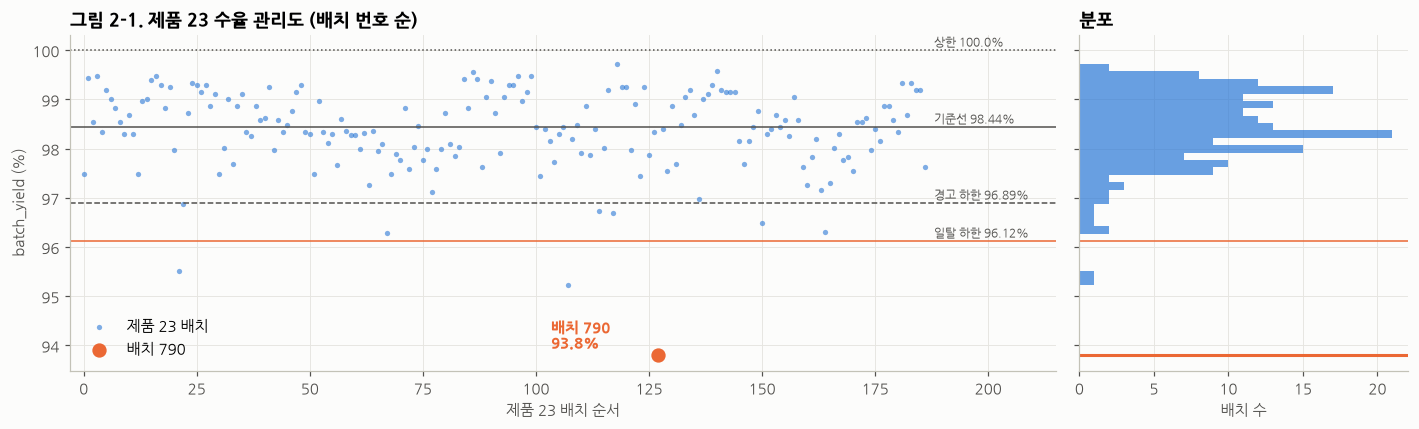

[견고성] 배치 790 이전 127개 배치만으로 산정한 일탈 하한: 96.07%  → 배치 790(93.80%) 판정: 일탈


In [6]:
sp = spec.loc[TARGET_CODE]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]}, sharey=True)

ax = axes[0]
ax.scatter(range(len(d23)), d23.batch_yield, s=12, color=C_NORMAL, alpha=0.6, linewidths=0, label="제품 23 배치")
pos = d23.index.get_loc(TARGET)
ax.scatter(pos, d23.loc[TARGET, "batch_yield"], s=70, color=C_LOW, zorder=3, label=f"배치 {TARGET}")
ax.annotate(f"배치 {TARGET}\n{d23.loc[TARGET, 'batch_yield']:.1f}%", (pos, d23.loc[TARGET, "batch_yield"]),
            xytext=(-70, 5), textcoords="offset points", color=C_LOW, fontweight="bold")
for y, lab_, ls in [(sp.기준선, f"기준선 {sp.기준선:.2f}%", "-"), (sp.경고_하한, f"경고 하한 {sp.경고_하한:.2f}%", "--"),
                    (sp.일탈_하한, f"일탈 하한 {sp.일탈_하한:.2f}%", "-"), (UPPER_LIMIT, "상한 100.0%", ":")]:
    ax.axhline(y, color=C_LOW if "일탈" in lab_ else C_TEXT2, lw=1, ls=ls)
    ax.text(len(d23) + 1, y + 0.04, lab_, va="bottom", fontsize=8, color=C_TEXT2)
ax.set(title="그림 2-1. 제품 23 수율 관리도 (배치 번호 순)", xlabel="제품 23 배치 순서", ylabel="batch_yield (%)",
       xlim=(-3, len(d23) + 28))
ax.legend(loc="lower left")

ax = axes[1]
ax.hist(ref23.batch_yield, bins=30, orientation="horizontal", color=C_NORMAL, alpha=0.7)
ax.axhline(d23.loc[TARGET, "batch_yield"], color=C_LOW, lw=2)
ax.axhline(sp.일탈_하한, color=C_LOW, lw=1)
ax.set(title="분포", xlabel="배치 수")
plt.tight_layout()
plt.show()

# 견고성 확인: '배치 790 이전' 이력만으로 규격을 정해도 일탈인가?
prior = d23.loc[d23.index < TARGET, "batch_yield"]
prior_limit = prior.median() - SIGMA_ACTION * robust_sigma(prior)
print(f"[견고성] 배치 {TARGET} 이전 {len(prior)}개 배치만으로 산정한 일탈 하한: {prior_limit:.2f}%  "
      f"→ 배치 {TARGET}({d23.loc[TARGET, 'batch_yield']:.2f}%) 판정: {'일탈' if d23.loc[TARGET, 'batch_yield'] < prior_limit else '정상'}")

> **해석**
>
> - 배치 790은 제품 23의 187개 배치 중 **가장 낮은 수율**이며, 일탈 하한보다 2.3%p 낮습니다.
> - 실제 현장처럼 **배치 790 이전 이력(127개)만으로 규격을 정해도** 하한은 96.07%로 거의 같고, 판정은 똑같이 일탈입니다.
>   전체 이력으로 정한 규격을 써도 결론이 바뀌지 않습니다.

---
## 3. STEP 2 — 5W1H 문제 정의

5W1H는 **원인을 말하기 전에 문제를 사실로 고정**하는 단계입니다.
그래서 "Why"는 이 단계에서 확정하지 않고, **관찰된 사실과 조사할 방향**만 적습니다.
5W1H를 쓰기 전에 배치 790의 생산 과정(3.1)과 손실 구성(3.2)을 먼저 확인합니다.

### 3.1 배치 790의 생산 과정 — 대표 정상 배치와 비교

**대표 정상 배치**: 제품 23에서 캠페인 첫 배치가 아니고, 셋업 시간·본생산 정지 시간이 모두 중앙값 이하인 배치 중
수율이 중앙값에 가장 가까운 배치입니다.

- 시간 축은 **배치 시작 후 경과 시간**입니다(타임스탬프 일·월 뒤바뀜 문제 회피, EDA 3.4).
- 누적 폐기량은 타정기 폐기 카운터의 **누적 최댓값**입니다. 카운터가 순간적으로 0으로 떨어지는 오류 샘플이 있어,
  증가분을 더하면 중복 집계되기 때문입니다(마지막 값이 `total_waste` × 9.6과 같은지 아래에서 확인).

배치 790 (일탈): 수율 93.80% | 셋업 250분 | 본생산 정지 118분 | 누적 폐기(시계열) 39,205 vs 기록 39,205
배치 686 (대표 정상): 수율 98.44% | 셋업 44분 | 본생산 정지 13분 | 누적 폐기(시계열) 13,813 vs 기록 13,813


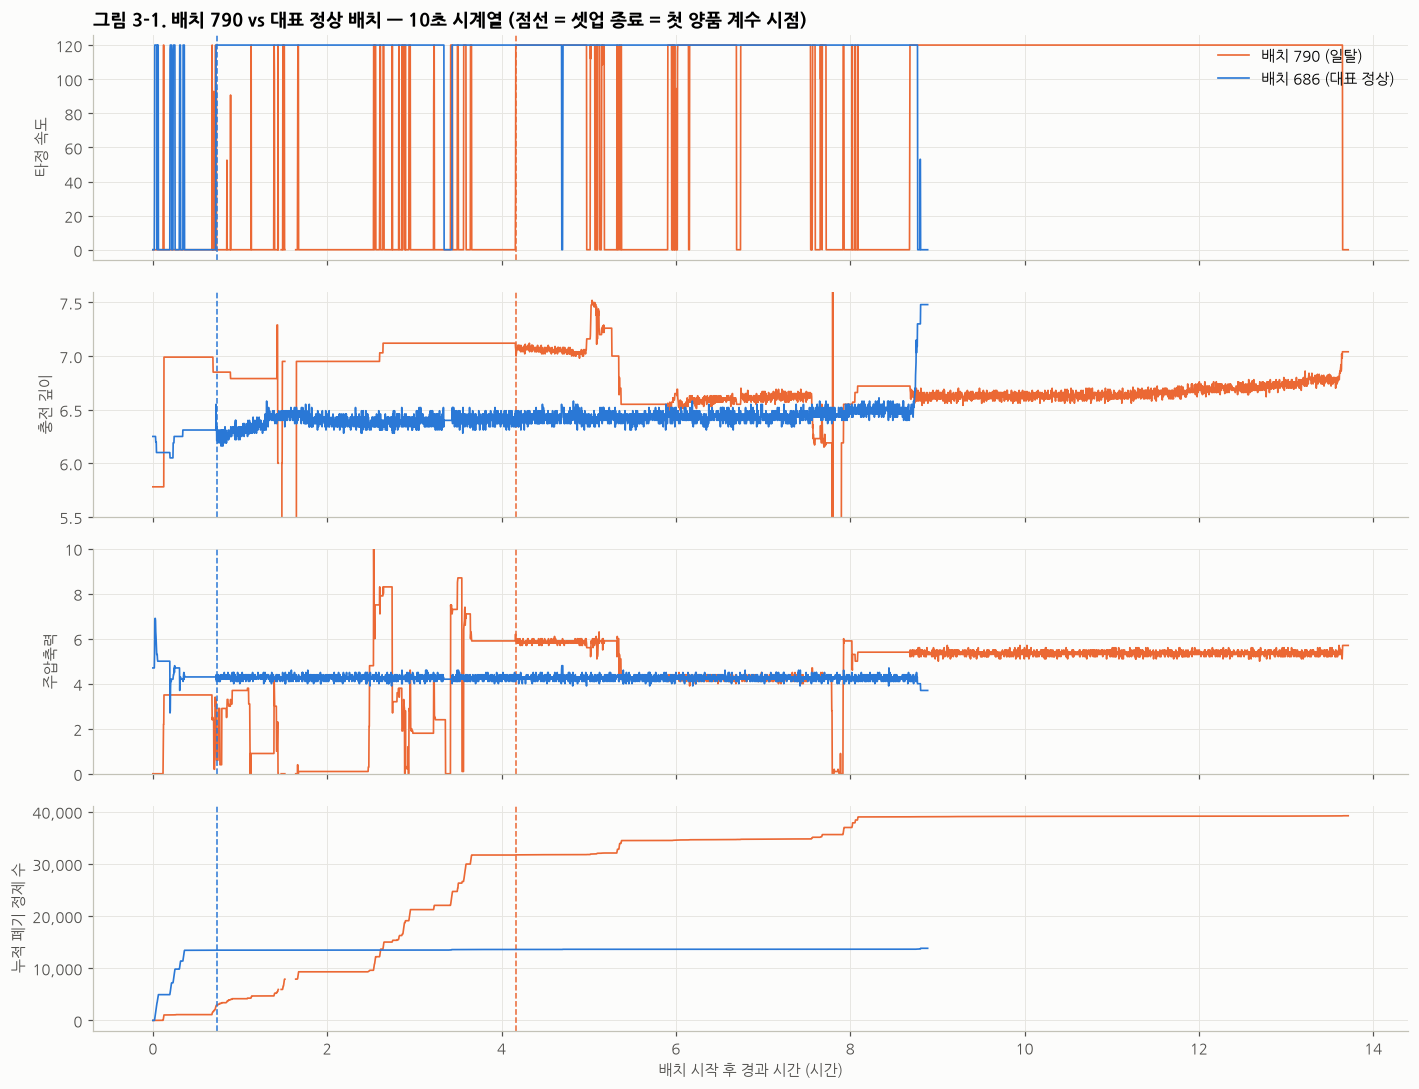

In [7]:
pool = ref23[(~ref23.first_in_campaign)
             & (ref23.setup_min <= ref23.setup_min.median())
             & (ref23.prod_stop_min <= ref23.prod_stop_min.median())]
NORMAL = (pool.batch_yield - ref23.batch_yield.median()).abs().idxmin()


def trace(b: int) -> pd.DataFrame:
    t = raw23[raw23.batch == b].reset_index(drop=True).copy()
    t["hours"] = t.index * 10 / 3600
    t["waste_cum"] = t.waste.cummax()
    return t


traces = {f"배치 {TARGET} (일탈)": (trace(TARGET), C_LOW, TARGET),
          f"배치 {NORMAL} (대표 정상)": (trace(NORMAL), C_NORMAL, NORMAL)}

for name, (t, _, b) in traces.items():
    rec = d23.loc[b, "total_waste"] * norm[TARGET_CODE]
    print(f"{name}: 수율 {d23.loc[b, 'batch_yield']:.2f}% | 셋업 {d23.loc[b, 'setup_min']:.0f}분 | "
          f"본생산 정지 {d23.loc[b, 'prod_stop_min']:.0f}분 | 누적 폐기(시계열) {t.waste_cum.iat[-1]:,.0f} vs 기록 {rec:,.0f}")

panels = [("tbl_speed", "타정 속도"), ("tbl_fill", "충전 깊이"), ("main_comp", "주압축력"), ("waste_cum", "누적 폐기 정제 수")]
fig, axes = plt.subplots(len(panels), 1, figsize=(13, 10), sharex=True)
for ax, (col, label) in zip(axes, panels):
    for name, (t, color, b) in traces.items():
        ax.plot(t.hours, t[col], color=color, lw=1.1, label=name)
        ax.axvline(d23.loc[b, "setup_min"] / 60, color=color, lw=1, ls="--")
    ax.set_ylabel(label)
axes[1].set_ylim(5.5, 7.6)                 # 정지 순간 센서 튐(충전 깊이 3.0) 제외하고 보기
axes[2].set_ylim(0, 10)
axes[3].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title("그림 3-1. 배치 790 vs 대표 정상 배치 — 10초 시계열 (점선 = 셋업 종료 = 첫 양품 계수 시점)")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("배치 시작 후 경과 시간 (시간)")
plt.tight_layout()
plt.show()

> **해석 — 배치 790에서 무슨 일이 있었나**
>
> - **셋업이 약 4시간(250분) 걸렸습니다.** 대표 정상 배치(686)는 44분입니다.
>   그 사이 충전 깊이(5.8~7.1)와 주압축력(0~10)을 여러 번 바꿨고, 대부분의 시간은 **기계가 멈춘 상태**였습니다.
>   누적 폐기 그래프는 이 4시간 동안 **약 3만 정이 계단식으로 쌓이는** 모습입니다.
> - 본생산에 들어간 뒤에도 **초반 약 4시간 동안 1시간 안팎의 긴 정지 2번을 포함해 정지·재시작이 반복**됐고,
>   긴 정지 전후로 충전 깊이 설정이 바뀌었습니다(약 7.1 → 6.55).
>   재시작할 때마다 폐기가 다시 계단처럼 올라갑니다(EDA 9장의 "재시작 손실"과 같은 패턴).
> - 마지막 약 5시간의 안정 운전 구간에서는 폐기가 거의 늘지 않습니다. 즉 **손실은 '셋업'과 '본생산 초반 정지·재시작'에 몰려 있습니다.**
> - 시계열 누적 폐기의 마지막 값은 `Process.csv` 기록(`total_waste` × 9.6)과 같아, 두 데이터가 서로 맞습니다.

### 3.2 손실 분해 (물질수지)

배치 크기(이론 정제 수) = 양품 + 손실, 손실 = **셋업 폐기 + 본생산 폐기 + 미기록 손실** 로 나눕니다.

- 셋업 폐기 = `startup_waste`, 본생산 폐기 = `total_waste` × 9.6 − `startup_waste`
- 미기록 손실 = 손실 − 타정기 폐기 기록 (잔류·집진·샘플링 등, 이 데이터에는 기록 없음)
- 질량(kg)은 정제 수 × 목표 정제 무게로 환산한 **추정치**입니다. 목표 정제 무게는 제품 23의 공정 중 검사(IPC) 최소·최대 무게 중간값의 중앙값(226 mg)으로 둡니다.

,배치 790 (정),손실 중 비중,제품 23 중앙값 (정),배치 790 / 중앙값
배치 크기(이론),"960,000",—,"960,000",1.0배
양품,"900,451",—,—,—
셋업 폐기,"31,712",53.3%,"6,780",4.7배
본생산 폐기,"7,493",12.6%,280,26.7배
미기록 손실,"20,344",34.2%,"4,850",4.2배


질량 환산(추정, 정제 1개 226 mg): 투입 216.96 kg → 양품 203.50 kg, 손실 13.46 kg


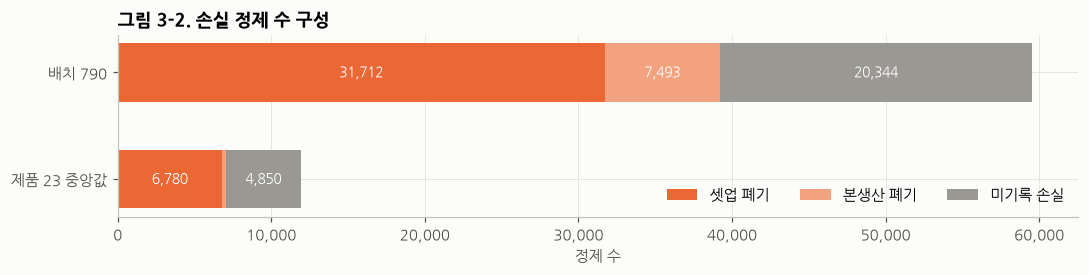

In [8]:
def loss_breakdown(row) -> pd.Series:
    loss = row["size"] * (100 - row.batch_yield) / 100
    setup = row.startup_waste
    recorded = row.total_waste * norm[TARGET_CODE]
    return pd.Series({"셋업 폐기": setup, "본생산 폐기": recorded - setup, "미기록 손실": loss - recorded, "손실 합계": loss})


lb = d23.apply(loss_breakdown, axis=1)
T = d23.loc[TARGET]
L = lb.loc[TARGET]
GOOD = T["size"] * T.batch_yield / 100
TABLET_MG = ((d23.tbl_min_weight + d23.tbl_max_weight) / 2).median()

mb = pd.DataFrame({
    f"배치 {TARGET} (정)": [T["size"], GOOD, *L[["셋업 폐기", "본생산 폐기", "미기록 손실"]]],
    "손실 중 비중": [np.nan, np.nan, *(L[["셋업 폐기", "본생산 폐기", "미기록 손실"]] / L["손실 합계"])],
    "제품 23 중앙값 (정)": [T["size"], np.nan, *lb.drop(index=TARGET)[["셋업 폐기", "본생산 폐기", "미기록 손실"]].median()],
}, index=["배치 크기(이론)", "양품", "셋업 폐기", "본생산 폐기", "미기록 손실"])
mb[f"배치 {TARGET} / 중앙값"] = mb[f"배치 {TARGET} (정)"] / mb["제품 23 중앙값 (정)"]
display(mb.style.format({f"배치 {TARGET} (정)": "{:,.0f}", "손실 중 비중": "{:.1%}", "제품 23 중앙값 (정)": "{:,.0f}",
                         f"배치 {TARGET} / 중앙값": "{:.1f}배"}, na_rep="—")
        .set_caption("표 3-1. 배치 790 물질수지와 손실 분해"))

MASS_IN = T["size"] * TABLET_MG / 1e6     # kg
MASS_OUT = GOOD * TABLET_MG / 1e6
print(f"질량 환산(추정, 정제 1개 {TABLET_MG:.0f} mg): 투입 {MASS_IN:,.2f} kg → 양품 {MASS_OUT:,.2f} kg, 손실 {MASS_IN - MASS_OUT:,.2f} kg")

fig, ax = plt.subplots(figsize=(10, 2.6))
parts = ["셋업 폐기", "본생산 폐기", "미기록 손실"]
colors = [C_LOW, "#f2a27f", C_GRAY]
for i, (rowname, vals) in enumerate([(f"배치 {TARGET}", L[parts]), ("제품 23 중앙값", lb.drop(index=TARGET)[parts].median())]):
    left = 0
    for p_, c_ in zip(parts, colors):
        ax.barh(i, vals[p_], left=left, color=c_, label=p_ if i == 0 else None, height=0.55)
        if vals[p_] > 3000:
            ax.text(left + vals[p_] / 2, i, f"{vals[p_]:,.0f}", ha="center", va="center", color="white", fontsize=9)
        left += vals[p_]
ax.set_yticks([0, 1], [f"배치 {TARGET}", "제품 23 중앙값"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set(title="그림 3-2. 손실 정제 수 구성", xlabel="정제 수")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

> **해석**
>
> - 손실 59,549정 중 **셋업 폐기가 53%(31,712정)** 로 가장 크고, 제품 23 중앙값의 4.7배입니다.
> - **본생산 폐기는 7,493정(13%)으로 중앙값의 27배**입니다. 비중은 작지만 평소와의 차이는 가장 큽니다.
> - 미기록 손실(34%)도 중앙값의 4.2배로 많습니다(제품 23에서 두 번째로 큼). 하지만 잔류·집진·샘플링 기록이 없어
>   **데이터로 원인을 좇을 수 없으므로 '조사 한계'로 남깁니다.**
> - 결론: **기록으로 추적 가능한 초과 손실은 '셋업'과 '본생산 중 정지·재시작' 두 구간에서 생겼습니다.** 4장 이후의 원인 탐색은 이 두 구간에 집중합니다.

### 3.3 발생 일시 확인

제품 23 시계열 파일은 `일월연도 시:분` 형식인데, 일부 배치는 **일과 월이 뒤바뀌어** 저장되어 있습니다(EDA 3.4).
배치 790의 원본 시작 시각은 `11092020 02:04` 로 그대로 읽으면 9월 11일입니다.
바로 다음 배치 791과 이어지는지 확인해 실제 날짜를 정합니다.

In [9]:
def first_last(b):
    t = raw23.loc[raw23.batch == b, "timestamp"]
    return t.iat[0], t.iat[-1]


for b in [TARGET, TARGET + 1]:
    s, e = first_last(b)
    print(f"배치 {b}: 원본 시작 {s}  ~  원본 종료 {e}   (start 월: {d23.loc[b, 'start']})")

raw_start = pd.to_datetime(first_last(TARGET)[0], format="%d%m%Y %H:%M")
EVENT_START = pd.Timestamp(year=raw_start.year, month=raw_start.day, day=raw_start.month,
                           hour=raw_start.hour, minute=raw_start.minute)          # 일·월 교환
raw_end = pd.to_datetime(first_last(TARGET)[1], format="%d%m%Y %H:%M")
EVENT_END = pd.Timestamp(year=raw_end.year, month=raw_end.day, day=raw_end.month,
                         hour=raw_end.hour, minute=raw_end.minute)                # 일·월 교환
SETUP_END = EVENT_START + pd.Timedelta(minutes=d23.loc[TARGET, "setup_min"])
print(f"\n→ 일·월 교환 시 배치 {TARGET}: {EVENT_START:%Y-%m-%d %H:%M} ~ {EVENT_END:%Y-%m-%d %H:%M}, "
      f"셋업 종료 {SETUP_END:%H:%M}")

배치 790: 원본 시작 11092020 02:04  ~  원본 종료 11092020 15:47   (start 월: okt.20)
배치 791: 원본 시작 09112020 15:51  ~  원본 종료 10112020 01:28   (start 월: okt.20)

→ 일·월 교환 시 배치 790: 2020-11-09 02:04 ~ 2020-11-09 15:47, 셋업 종료 06:14


> **해석**
>
> - 배치 791은 `09112020 15:51`(2020-11-09 15:51)에 시작합니다. 배치 790의 원본 날짜를 일·월 교환해 **2020-11-09** 로 읽으면,
>   790이 15:47에 끝나고 4분 뒤 791이 시작해 **시간이 정확히 이어집니다.**
> - 따라서 배치 790의 실제 생산 일시는 **2020-11-09 02:04 ~ 15:47** 이고, 셋업은 **02:04 ~ 06:14** 입니다.

### 3.4 5W1H 문제 정의

In [10]:
ref_med = ref23.batch_yield.median()
ref_mean = ref23.batch_yield.mean()
E = {   # 이후 보고서·5 Why 에서 같은 숫자를 쓰기 위해 한곳에 모아 둔다
    "yield": T.batch_yield, "ref_mean": ref_mean, "ref_med": ref_med, "n_ref": len(ref23),
    "limit": sp.일탈_하한, "alert": sp.경고_하한, "gap_limit": T.batch_yield - sp.일탈_하한, "gap_mean": T.batch_yield - ref_mean,
    "loss": L["손실 합계"], "good": GOOD, "setup_w": L["셋업 폐기"], "prod_w": L["본생산 폐기"], "unrec": L["미기록 손실"],
    "setup_min": T.setup_min, "setup_med": ref23.setup_min.median(), "setup_idle": T.setup_idle_min,
    "pstop": T.prod_stop_min, "pstop_med": ref23.prod_stop_min.median(),
    "nstops": T.prod_long_stops, "nstops_med": ref23.prod_long_stops.median(),
    "campaign": int(T.campaign),
}
E["setup_share"], E["prod_share"], E["unrec_share"] = E["setup_w"] / E["loss"], E["prod_w"] / E["loss"], E["unrec"] / E["loss"]

w5h1 = pd.DataFrame([
    ("What (무엇이)", f"제품 23(20 mg 정제) 배치 {TARGET}의 배치 수율이 **{E['yield']:.1f}%** 로, 일탈 하한 {E['limit']:.1f}%를 "
                     f"{abs(E['gap_limit']):.1f}%p 밑돌았다 (참조 배치 평균 {E['ref_mean']:.1f}% 대비 {E['gap_mean']:+.1f}%p)."),
    ("When (언제)", f"{EVENT_START:%Y-%m-%d %H:%M} ~ {EVENT_END:%H:%M} (캠페인 {E['campaign']}의 **첫 배치**, 제품 교체 직후). "
                    f"손실은 셋업 구간({EVENT_START:%H:%M}~{SETUP_END:%H:%M})과 본생산 초반에 집중."),
    ("Where (어디서)", "**타정 공정** (배치 수율 = 타정 수율, 이후 공정 손실 없음). "
                      f"손실 위치: 셋업 {E['setup_share']:.0%} · 본생산 {E['prod_share']:.0%} · 미기록 {E['unrec_share']:.0%}."),
    ("Who (누가)", "발견·보고: 공정 엔지니어(배치 종료 후 수율 집계) [가상]. "
                   f"관련: {EVENT_START:%H}시에 셋업을 시작한 **야간조 셋업 작업자** (데이터에 인력 정보 없음)."),
    ("Why (왜)", "**미확정 — RCA로 규명.** 관찰된 사실: "
                 f"셋업 {E['setup_min']:.0f}분(중앙값 {E['setup_med']:.0f}분의 {E['setup_min'] / E['setup_med']:.1f}배), "
                 f"본생산 중 정지 {E['pstop']:.0f}분(중앙값 {E['pstop_med']:.0f}분의 {E['pstop'] / E['pstop_med']:.1f}배)."),
    ("How (어떻게·얼마나)", f"이론 {T['size']:,.0f}정 중 양품 {E['good']:,.0f}정, 손실 **{E['loss']:,.0f}정** "
                          f"= 셋업 폐기 {E['setup_w']:,.0f} + 본생산 폐기 {E['prod_w']:,.0f} + 미기록 {E['unrec']:,.0f}. "
                          "셋업 중 충전 깊이·압축력을 반복 조정하며 정지가 길어졌고, 본생산 중 재시작마다 폐기가 계단식으로 증가."),
], columns=["항목", "내용"])
display(Markdown("| 항목 | 내용 |\n|---|---|\n" + "\n".join(f"| **{k}** | {v} |" for k, v in w5h1.itertuples(index=False))))

| 항목 | 내용 |
|---|---|
| **What (무엇이)** | 제품 23(20 mg 정제) 배치 790의 배치 수율이 **93.8%** 로, 일탈 하한 96.1%를 2.3%p 밑돌았다 (참조 배치 평균 98.4% 대비 -4.6%p). |
| **When (언제)** | 2020-11-09 02:04 ~ 15:47 (캠페인 154의 **첫 배치**, 제품 교체 직후). 손실은 셋업 구간(02:04~06:14)과 본생산 초반에 집중. |
| **Where (어디서)** | **타정 공정** (배치 수율 = 타정 수율, 이후 공정 손실 없음). 손실 위치: 셋업 53% · 본생산 13% · 미기록 34%. |
| **Who (누가)** | 발견·보고: 공정 엔지니어(배치 종료 후 수율 집계) [가상]. 관련: 02시에 셋업을 시작한 **야간조 셋업 작업자** (데이터에 인력 정보 없음). |
| **Why (왜)** | **미확정 — RCA로 규명.** 관찰된 사실: 셋업 250분(중앙값 48분의 5.2배), 본생산 중 정지 118분(중앙값 15분의 7.7배). |
| **How (어떻게·얼마나)** | 이론 960,000정 중 양품 900,451정, 손실 **59,549정** = 셋업 폐기 31,712 + 본생산 폐기 7,493 + 미기록 20,344. 셋업 중 충전 깊이·압축력을 반복 조정하며 정지가 길어졌고, 본생산 중 재시작마다 폐기가 계단식으로 증가. |

> **정리** — 문제 문장: *"2020-11-09 타정 공정에서 제품 23 배치 790(캠페인 첫 배치)의 수율이 93.8%로 일탈 하한 96.1%에 미달했다.
> 손실 59,549정의 53%는 250분간 이어진 셋업에서, 13%는 본생산 중 정지·재시작에서 발생했다."*

---
## 4. STEP 3 — 수율 이상 발생 보고서

팀 공용 양식의 **발생보고서 탭** 항목을 그대로 따릅니다. 숫자는 모두 앞 장의 계산값에서 가져오며,
데이터에 없는 항목(보고자, 발견·보고 시각, 초기 조치)은 **[가상]** 으로 표시한 예시입니다.

In [11]:
def form_html(title: str, doc_no: str, rows: list) -> str:
    """팀 보고서 양식(4열: 구분|내용|구분|내용) 형태의 HTML 표.
    rows 원소: ("§", 섹션명) | (항목, 내용) | (항목1, 내용1, 항목2, 내용2)"""
    th = 'style="background:#f1f0ec;text-align:left;padding:6px 8px;white-space:nowrap;vertical-align:top"'
    td = 'style="text-align:left;padding:6px 8px;vertical-align:top"'
    sec = 'style="background:#2a3b4c;color:white;text-align:left;padding:6px 8px;font-weight:bold"'
    h = [f'<h3 style="margin-bottom:2px">{title}</h3><p style="margin-top:0;color:#52514e">문서번호: {doc_no}</p>',
         '<table style="border-collapse:collapse;width:100%;font-size:13px" border="1">',
         f"<tr><th {th}>구분</th><th {th}>상세 기재 내용</th><th {th}>구분</th><th {th}>상세 기재 내용</th></tr>"]
    for r in rows:
        if r[0] == "§":
            h.append(f'<tr><td colspan="4" {sec}>{r[1]}</td></tr>')
        elif len(r) == 2:
            h.append(f'<tr><th {th}>{r[0]}</th><td colspan="3" {td}>{r[1]}</td></tr>')
        else:
            h.append(f"<tr><th {th}>{r[0]}</th><td {td}>{r[1]}</td><th {th}>{r[2]}</th><td {td}>{r[3]}</td></tr>")
    h.append("</table>")
    return "\n".join(h)


# 출하 품질이 제품 23 다른 배치의 관측 범위 안인지 확인 (품질 영향 평가 근거)
q_rows = []
for c, name in [("dissolution_av", "용출 평균(%)"), ("dissolution_min", "용출 최소(%)"), ("impurities_total", "총 불순물(%)")]:
    lo, hi = ref23[c].min(), ref23[c].max()
    q_rows.append(f"{name} {T[c]:.2f} (제품 23 범위 {lo:.2f}~{hi:.2f}, {'범위 내' if lo <= T[c] <= hi else '범위 밖'})")
QUALITY_NOTE = " · ".join(q_rows)
print(QUALITY_NOTE)

INC_NO = f"INC-{EVENT_START:%Y-%m%d}-{TARGET}"
report1 = form_html("수율 이상 발생 보고서", f"{INC_NO} <i>(예시 번호)</i>", [
    ("발생 일시", f"{EVENT_START:%Y.%m.%d. %H:%M}~{EVENT_END:%H:%M} (배치 진행 구간)<br>손실 집중: {EVENT_START:%H:%M}~{SETUP_END:%H:%M} 셋업 구간",
     "최초 발견 일시", f"{EVENT_END + pd.Timedelta(minutes=15):%Y.%m.%d. %H:%M} [가상] (배치 종료 후 수율 집계)"),
    ("보고 일시", f"{EVENT_END + pd.Timedelta(minutes=45):%Y.%m.%d. %H:%M} [가상]", "보고자", "공정 엔지니어 (가명) [가상]"),
    ("대상 제품", "제품 23 (20 mg 정제, 배치 크기 960,000정)", "배치 번호", f"{TARGET} (캠페인 {E['campaign']} 첫 배치)"),
    ("발생 공정", "타정", "설비명 (번호)", "타정기 (설비 번호는 데이터 미제공)"),
    ("발생 유형", "[ ] 수율 이상 &nbsp; <b>[X] 수율 일탈</b>", "관할 부서", "생산기술팀 (공정 엔지니어)"),
    ("§", "2. 발생 및 수율 상세 내용"),
    ("대상 수율", f"<b>{E['yield']:.1f}%</b>", "비교 배치 / 평균 수율", f"{E['n_ref']}개 배치 / 평균 {E['ref_mean']:.1f}% (중앙값 {E['ref_med']:.1f}%)"),
    ("수율 차이", f"<b>{E['gap_mean']:+.1f}%p</b>", "현장 점검 결과",
     f"타정기 기록 점검: 셋업 {E['setup_min']:.0f}분 소요(이 중 정지 {E['setup_idle']:.0f}분), 본생산 중 1분 이상 정지 {E['nstops']:.0f}회"),
    ("발생 내용 상세",
     f"이론 {T['size']:,.0f}정 중 양품 {E['good']:,.0f}정 회수. 셋업 폐기 {E['setup_w']:,.0f}정, 본생산 폐기 {E['prod_w']:,.0f}정, "
     f"미기록 손실(잔류·집진·샘플링 등) {E['unrec']:,.0f}정. 셋업 중 충전 깊이·주압축력 설정을 여러 차례 변경하며 정지 상태가 길게 이어졌고, "
     "본생산 초반 두 차례 장시간 정지 후 재시작 시 폐기가 증가함. 발생 원인은 미확정."),
    ("§", "3. 수율 산정 기준 및 판정"),
    ("투입 질량", f"{MASS_IN:,.2f} kg (추정: {T['size']:,.0f}정 × {TABLET_MG:.0f} mg)", "회수 질량", f"{MASS_OUT:,.2f} kg (추정, 양품 정제)"),
    ("공정 경계", "타정기 투입(최종 혼합 분말)부터 양품 정제 계수 완료까지. 수율 = 양품 정제 수 ÷ 배치 크기(이론 정제 수) × 100. "
                  "(본 배치는 배치 수율 = 타정 수율로, 타정 이후 공정 손실 없음)"),
    ("적용 허용범위", f"{E['limit']:.1f}% ~ {UPPER_LIMIT:.1f}% (제품 23 통계적 관리 기준: 중앙값 − 3σ̂, 2.1절)",
     "수율 허용범위 판정", "[ ] 허용범위 내 &nbsp; <b>[X] 하한 미달</b> &nbsp; [ ] 상한 초과 &nbsp; [ ] 판정 대기"),
    ("§", "4. 제품 품질 영향 평가"),
    ("초기 원인 추정 및 공정 영향",
     "셋업 장기화와 본생산 중 정지·재시작에 따른 폐기 증가를 우선 조사한다. 제품 교체 셋업 방법, 설비 상태, 원료 물성, "
     "측정(무게 판정) 시스템, 인력·환경을 원인 후보로 검토하며 확정 원인은 없다. "
     f"출하 품질 시험 결과: {QUALITY_NOTE}. 최종 품질 영향은 QA 평가 중."),
    ("§", "5. 초기 조치 및 담당자·실시 현황"),
    ("초기 조치 내용", "[가상] 배치 식별·격리, 후속 공정 이송 보류. 타정기 운전 기록(10초 시계열) 및 IPC 기록 보존.",
     "담당자", "공정 엔지니어 (가명) [가상]"),
    ("실시 일시", f"{EVENT_END + pd.Timedelta(minutes=20):%Y.%m.%d. %H:%M}~{EVENT_END + pd.Timedelta(minutes=40):%H:%M} [가상]",
     "완료 여부", "<b>[X] 완료</b> &nbsp; [ ] 진행 중 (초기 조치 기준)"),
    ("제품 처분 상태", "<b>[X] 출하 보류 및 격리</b> &nbsp; [ ] 폐기 &nbsp; [ ] 재가공 &nbsp; [ ] 기타 — 최종 처분은 QA 평가 후 결정"),
])
display(HTML(report1))

용출 평균(%) 95.17 (제품 23 범위 83.67~99.83, 범위 내) · 용출 최소(%) 91.00 (제품 23 범위 74.00~98.00, 범위 내) · 총 불순물(%) 0.25 (제품 23 범위 0.17~0.40, 범위 내)


---
## 5. STEP 4 — 6M 관점별 원인 후보 도출

### 5.1 후보 도출 방식

- 6M(인력·설비·자재·방법·측정·환경) 관점마다 **1~3개**의 원인 후보를 세웁니다.
- 각 후보에는 **데이터로 확인할 지표**와 **가설 방향**(지표가 클수록/작을수록 수율이 나빠진다)을 붙입니다.
- **관찰 근거**: 배치 790의 지표가 제품 23 참조 배치(186개)와 비교해 가설 방향으로 얼마나 극단인지 봅니다.
  - 연속 지표: 극단 백분위 = 참조 배치 중 790만큼 (또는 더) 극단인 배치의 비율. **5% 미만이면 '이상 관찰'**.
  - 예/아니오 지표: 790이 해당 조건에 있으면 '해당'.
- 증상 변수(`total_waste`, `startup_waste`)는 원인 지표에서 뺍니다(0.2절).
- 환경(온·습도) 데이터는 수집되지 않아 **생산 계절을 대리 지표**로 씁니다.

In [12]:
HYP = pd.DataFrame([
    # id, 6M, 원인 후보, 지표, 유형, 방향(+: 클수록 나쁨, -: 작을수록 나쁨), 지표 설명
    ("MAN-1", "인력", "야간 시간대 셋업 착수 (숙련 인력·지원 부족)", "night_start", "bin", +1, "배치 시작 22~06시"),
    ("MAN-2", "인력", "주말 생산 (인력 축소 운영)", "is_weekend", "bin", +1, "주말 생산 여부"),
    ("MAC-1", "설비", "본생산 중 장시간 정지·재시작 반복", "prod_stop_min", "cont", +1, "본생산 중 정지 시간(분)"),
    ("MAC-2", "설비", "주압축력 변동 (압축부 불안정)", "main_CompForce_sd", "cont", +1, "주압축력 표준편차"),
    ("MAC-3", "설비", "정제 배출력 과다 (금형·펀치 마찰)", "ejection_max", "cont", +1, "배출력 최댓값"),
    ("MAT-1", "자재", "API 입도가 미세한 로트 (유동성 저하)", "api_ps09", "cont", -1, "API 입도 D90(μm)"),
    ("MAT-2", "자재", "API 수분 과다 (뭉침·부착)", "api_water", "cont", +1, "API 수분(%)"),
    ("MET-1", "방법", "제품 교체 셋업 장기화 (표준 셋업 조건 부재)", "setup_min", "cont", +1, "셋업 시간(분)"),
    ("MET-2", "방법", "충전 조건 수동 조정 반복", "fom_change", "cont", +1, "충전 장치 속도 변경 횟수"),
    ("MEA-1", "측정", "셋업 중 압축력 기반 무게 판정 신호(SREL) 과변동 → 과다 배출 판정", "SREL_startup_mean", "cont", +1, "셋업 단계 SREL 평균"),
    ("MEA-2", "측정", "정제 무게 편차 증가 (IPC)", "tbl_rsd_weight", "cont", +1, "정제 무게 RSD(%)"),
    ("ENV-1", "환경", "계절(가을) 온·습도 변화 (대리 지표)", "autumn", "bin", +1, "가을(9~11월) 생산 여부"),
], columns=["id", "6M", "원인 후보", "지표", "유형", "방향", "지표 설명"]).set_index("id")

d23["is_weekend"] = d23.weekend.eq("yes")
ref23 = d23.drop(index=TARGET)


def extremity(var: str, direction: int) -> float:
    """참조 배치 중 790만큼(또는 더) 가설 방향으로 극단인 비율 = 경험적 단측 p 값."""
    x, v = ref23[var].dropna(), d23.loc[TARGET, var]
    k = (x >= v).sum() if direction > 0 else (x <= v).sum()
    return (k + 1) / (len(x) + 1)


obs = []
for hid, h in HYP.iterrows():
    v = d23.loc[TARGET, h.지표]
    if h.유형 == "cont":
        ext = extremity(h.지표, h.방향)
        obs.append({"790 값": f"{v:,.2f}", "참조 중앙값": f"{ref23[h.지표].median():,.2f}",
                    "극단 백분위": ext, "관찰 판정": "이상 관찰" if ext < 0.05 else "해당 없음"})
    else:
        rate = ref23[h.지표].mean()
        obs.append({"790 값": "예" if v else "아니오", "참조 중앙값": f"참조 중 {rate:.0%}",
                    "극단 백분위": np.nan, "관찰 판정": "해당" if v else "해당 없음"})
HYP = HYP.join(pd.DataFrame(obs, index=HYP.index))

(HYP[["6M", "원인 후보", "지표 설명", "790 값", "참조 중앙값", "극단 백분위", "관찰 판정"]]
 .style.format({"극단 백분위": "{:.1%}"}, na_rep="—")
 .apply(lambda r: ["color: #9a9893" if r["관찰 판정"] == "해당 없음" else "" for _ in r], axis=1)
 .set_caption("표 5-1. 6M 원인 후보 12개와 배치 790의 관찰 근거 (회색 = 790에서 관찰되지 않음)"))

,6M,원인 후보,지표 설명,790 값,참조 중앙값,극단 백분위,관찰 판정
id,,,,,,,
MAN-1,인력,야간 시간대 셋업 착수 (숙련 인력·지원 부족),배치 시작 22~06시,예,참조 중 35%,—,해당
MAN-2,인력,주말 생산 (인력 축소 운영),주말 생산 여부,아니오,참조 중 3%,—,해당 없음
MAC-1,설비,본생산 중 장시간 정지·재시작 반복,본생산 중 정지 시간(분),118.17,15.25,3.7%,이상 관찰
MAC-2,설비,주압축력 변동 (압축부 불안정),주압축력 표준편차,0.52,0.11,1.6%,이상 관찰
MAC-3,설비,정제 배출력 과다 (금형·펀치 마찰),배출력 최댓값,293.00,235.00,23.0%,해당 없음
MAT-1,자재,API 입도가 미세한 로트 (유동성 저하),API 입도 D90(μm),101.13,146.96,1.1%,이상 관찰
MAT-2,자재,API 수분 과다 (뭉침·부착),API 수분(%),1.04,1.22,75.4%,해당 없음
MET-1,방법,제품 교체 셋업 장기화 (표준 셋업 조건 부재),셋업 시간(분),250.17,48.50,0.5%,이상 관찰
MET-2,방법,충전 조건 수동 조정 반복,충전 장치 속도 변경 횟수,84.00,12.00,0.5%,이상 관찰


> **해석**
>
> - 12개 후보 중 **9개가 배치 790에서 실제로 관찰**됩니다. 주말 생산(MAN-2), 배출력(MAC-3), API 수분(MAT-2)은 790에서 평소와 같아 후보에서 내려갑니다.
> - 가장 극단적인 것은 **셋업 시간(MET-1)·충전 장치 조정 횟수(MET-2)·셋업 단계 SREL(MEA-1)** 로, 참조 186개 배치 중 790보다 극단인 배치가 하나도 없습니다(0.5% = 최소값).
> - 원료 쪽에서는 **API 입도(MAT-1)가 하위 1%** 로 눈에 띄게 미세했습니다.
> - 다만 **'790에서 극단적이다'는 것만으로는 원인이 아닙니다.** 그 조건이 평소에도 수율 저하와 함께 나타나는지는 7장에서 검정합니다.

### 5.2 특성요인도 (초기 가설)

팀 RCA 보고서 양식의 표시 규칙을 따릅니다: **[H] 초기 가설 / [R] 채택된 근본원인 / 실선 = 검증 근거 확보 / 점선 = 미검증 연결**.
이 단계에서는 모든 후보가 미검증 가설([H], 점선)입니다.

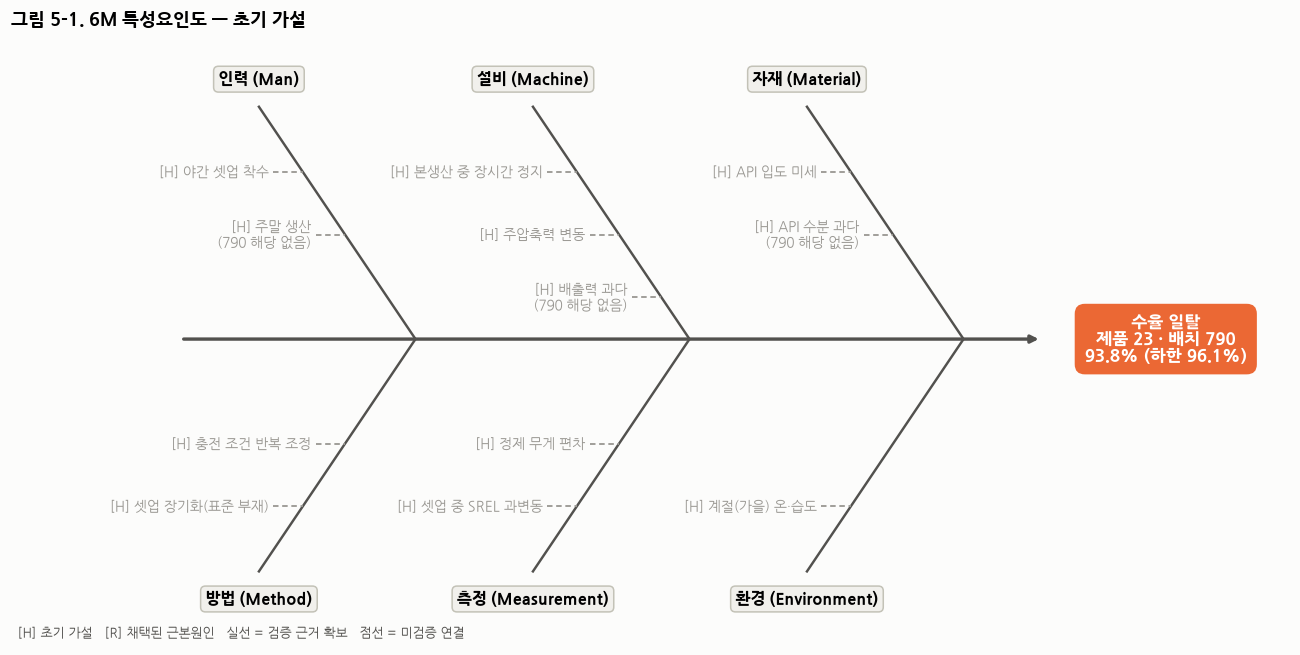

In [13]:
SHORT = {"MAN-1": "야간 셋업 착수", "MAN-2": "주말 생산", "MAC-1": "본생산 중 장시간 정지", "MAC-2": "주압축력 변동",
         "MAC-3": "배출력 과다", "MAT-1": "API 입도 미세", "MAT-2": "API 수분 과다", "MET-1": "셋업 장기화(표준 부재)",
         "MET-2": "충전 조건 반복 조정", "MEA-1": "셋업 중 SREL 과변동", "MEA-2": "정제 무게 편차", "ENV-1": "계절(가을) 온·습도"}
M_ORDER = [("인력", "Man"), ("설비", "Machine"), ("자재", "Material"),
           ("방법", "Method"), ("측정", "Measurement"), ("환경", "Environment")]


def draw_fishbone(status: dict, title: str, head: str):
    """status[id] = (표시 태그, 실선 여부, 강조 여부, 꼬리표)"""
    fig, ax = plt.subplots(figsize=(15, 7.2))
    ax.set_xlim(-3.2, 16.4)
    ax.set_ylim(-4.2, 4.2)
    ax.axis("off")
    ax.annotate("", xy=(12.6, 0), xytext=(-0.6, 0), arrowprops=dict(arrowstyle="-|>", lw=2.2, color=C_TEXT2))
    ax.text(14.5, 0, head, ha="center", va="center", fontsize=11, fontweight="bold", color="white",
            bbox=dict(boxstyle="round,pad=0.6", fc=C_LOW, ec="none"))
    for k, (m_ko, m_en) in enumerate(M_ORDER):
        top = k < 3
        x1 = [3.0, 7.2, 11.4][k % 3]
        x0, y0 = x1 - 2.4, (3.2 if top else -3.2)
        ax.plot([x0, x1], [y0, 0], color=C_TEXT2, lw=1.6)
        ax.text(x0, y0 + (0.38 if top else -0.38), f"{m_ko} ({m_en})", ha="center", va="center", fontsize=10.5,
                fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#f1f0ec", ec="#c3c2b7"))
        ids = HYP.index[HYP["6M"] == m_ko]
        for j, hid in enumerate(ids):
            tag, solid, strong, note = status[hid]
            t = [0.28, 0.55, 0.82][j]
            px, py = x0 + t * (x1 - x0), y0 + t * (0 - y0)
            color = C_LOW if strong else (C_TEXT2 if solid else C_GRAY)
            ax.plot([px - 0.45, px], [py, py], color=color, lw=1.8 if strong else 1.2, ls="-" if solid else (0, (3, 2)))
            ax.text(px - 0.52, py, f"[{tag}] {SHORT[hid]}" + (f"\n{note}" if note else ""), ha="right", va="center",
                    fontsize=9, color=color, fontweight="bold" if strong else "normal", linespacing=1.15)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.text(-3.1, -4.1, "[H] 초기 가설   [R] 채택된 근본원인   실선 = 검증 근거 확보   점선 = 미검증 연결",
            fontsize=8.5, color=C_TEXT2)
    plt.show()


HEAD = f"수율 일탈\n제품 23 · 배치 {TARGET}\n{E['yield']:.1f}% (하한 {E['limit']:.1f}%)"
draw_fishbone({hid: ("H", False, False, "(790 해당 없음)" if HYP.loc[hid, "관찰 판정"] == "해당 없음" else "")
               for hid in HYP.index},
              "그림 5-1. 6M 특성요인도 — 초기 가설", HEAD)

---
## 6. STEP 5 — 6M 관점별 5 Why

### 6.1 작성 규칙

- 관점마다 5 Why 경로를 **하나씩** 만듭니다(총 6개). 출발점은 그 관점의 후보 중 **790에서 관찰되고 손실 경로(3.2절)와 직접 이어지는 후보**입니다.
- **Why 1은 항상 같은 문제 문장**에서 출발합니다: "왜 수율이 93.8%로 떨어졌나?"
- 각 답에는 근거를 표시합니다.
  - **[데이터]**: 이 노트북의 데이터로 확인한 사실 (수치 포함)
  - **[추정]**: 데이터로 확인할 수 없어 현장 기록·인터뷰로 확인해야 하는 내용
- **Why 5의 답 = 근본원인 후보**입니다. 근본원인은 대개 '관리 체계'(표준·기준·절차)의 빈틈이라 데이터로 직접 볼 수 없으므로,
  경로 중 **데이터로 검정할 수 있는 고리(검증 지표)** 를 함께 지정합니다. 이 고리가 7장의 검정 대상입니다.

In [14]:
# 5 Why 에 들어갈 근거 수치 (모두 앞 장에서 계산한 값)
def pct(hid):  # 극단 백분위 → "상위/하위 x%" 문구
    return f"{'상위' if HYP.loc[hid, '방향'] > 0 else '하위'} {HYP.loc[hid, '극단 백분위']:.1%}"


V = lambda col: d23.loc[TARGET, col]        # noqa: E731
M = lambda col: ref23[col].median()         # noqa: E731
Q1 = f"왜 배치 {TARGET}의 수율이 {E['yield']:.1f}%로 떨어졌나?"

FIVE_WHY = {
    "인력": {"start": "MAN-1", "chain": [
        (Q1, f"셋업 단계에서 {E['setup_w']:,.0f}정이 폐기됐다 (손실의 {E['setup_share']:.0%}).", "데이터"),
        ("왜 셋업 폐기가 많았나?", f"셋업이 {E['setup_min']:.0f}분 걸렸다 (제품 23 중앙값 {E['setup_med']:.0f}분).", "데이터"),
        ("왜 셋업이 길어졌나?", f"셋업 {E['setup_min']:.0f}분 중 {E['setup_idle']:.0f}분({E['setup_idle'] / E['setup_min']:.0%})이 정지 상태였다. "
                              "설정을 바꾼 뒤 다음 시도까지 대기가 길었다.", "데이터"),
        ("왜 대기가 길었나?", f"{EVENT_START:%H:%M} 야간 착수로 숙련 셋업 인력·QC 확인 지원을 즉시 받지 못했다.", "추정"),
        ("왜 지원을 받지 못했나?", "**야간 제품 교체 셋업에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.**", "추정"),
    ], "test": "야간 착수 배치는 수율이 낮은가?"},
    "설비": {"start": "MAC-1", "chain": [
        (Q1, f"본생산 중 {E['prod_w']:,.0f}정이 폐기됐다 (제품 23 중앙값의 {E['prod_w'] / lb.drop(index=TARGET)['본생산 폐기'].median():.0f}배).", "데이터"),
        ("왜 본생산 폐기가 많았나?", f"본생산 중 정지가 {E['pstop']:.0f}분(중앙값 {E['pstop_med']:.0f}분), 1분 이상 정지가 {E['nstops']:.0f}회였고 "
                                    "재시작마다 폐기가 계단식으로 늘었다 (그림 3-1).", "데이터"),
        ("왜 정지가 길었나?", "운전 중 조건이 벗어나 설비를 세우고 재조정했다. 긴 정지 전후로 충전 깊이 설정이 바뀌었다(약 7.1 → 6.55).", "데이터"),
        ("왜 운전 중 조건이 벗어났나?", f"압축부가 불안정했다: 주압축력 표준편차 {V('main_CompForce_sd'):.2f} (중앙값 {M('main_CompForce_sd'):.2f}, {pct('MAC-2')}).", "데이터"),
        ("왜 압축부 불안정이 생산 중에 드러났나?", "**재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검 기준이 없어, 불안정한 상태로 운전·정지를 반복했다.**", "추정"),
    ], "test": "본생산 중 정지가 길수록 수율이 낮은가?"},
    "자재": {"start": "MAT-1", "chain": [
        (Q1, f"셋업·본생산 중 무게를 맞추려 충전 조건을 반복 조정하며 폐기가 늘었다 (충전 장치 속도 변경 {V('fom_change'):.0f}회, 중앙값 {M('fom_change'):.0f}회).", "데이터"),
        ("왜 충전 조건을 반복 조정했나?", "같은 충전 깊이에서 목표 무게가 나오지 않았다 — 혼합 분말의 밀도·흐름성이 평소와 달랐다.", "추정"),
        ("왜 분말 특성이 달랐나?", f"API 입도가 매우 미세했다: D90 {V('api_ps09'):.0f} μm (중앙값 {M('api_ps09'):.0f} μm, {pct('MAT-1')}).", "데이터"),
        ("왜 미세한 로트가 투입됐나?", "해당 로트가 수입 시험 규격에는 적합이었다.", "추정"),
        ("왜 규격에 적합인데 문제가 됐나?", "**API 입도 규격이 타정 공정 적합성(흐름성)을 반영한 하한을 두지 않는다.**", "추정"),
    ], "test": "API 입도(D90)가 작을수록 수율이 낮은가?"},
    "방법": {"start": "MET-1", "chain": [
        (Q1, f"셋업 단계에서 {E['setup_w']:,.0f}정이 폐기됐다 (손실의 {E['setup_share']:.0%}).", "데이터"),
        ("왜 셋업 폐기가 많았나?", f"셋업이 {E['setup_min']:.0f}분 걸렸다 (중앙값 {E['setup_med']:.0f}분의 {E['setup_min'] / E['setup_med']:.1f}배, {pct('MET-1')}).", "데이터"),
        ("왜 셋업이 길어졌나?", f"충전 깊이·주압축력을 시행착오로 반복 조정했다: 충전 장치 속도 변경 {V('fom_change'):.0f}회 "
                              f"(중앙값 {M('fom_change'):.0f}회), 셋업 중 충전 깊이 최대 변화폭 {V('Startup_tbl_fill_maxDifference'):.2f} "
                              f"(중앙값 {M('Startup_tbl_fill_maxDifference'):.2f}).", "데이터"),
        ("왜 시행착오로 조정했나?", f"캠페인 {E['campaign']}의 **첫 배치**(제품 교체 직후)로, 직전 제품 조건에서 출발해 제품 23 조건을 찾아가야 했다.", "데이터"),
        ("왜 조건을 '찾아가야' 했나?", "**제품별 표준 셋업 조건(초기 충전 깊이·압축력 레시피)과 셋업 완료 판정 기준이 정립되어 있지 않다.**", "추정"),
    ], "test": "셋업이 길수록 수율이 낮은가?"},
    "측정": {"start": "MEA-1", "chain": [
        (Q1, f"셋업 단계에서 {E['setup_w']:,.0f}정이 '불량'으로 판정되어 자동 배출됐다.", "데이터"),
        ("왜 불량 판정이 많았나?", f"셋업 중 압축력 기반 무게 판정 신호(SREL)가 크게 흔들렸다: 평균 {V('SREL_startup_mean'):.1f} "
                                  f"(중앙값 {M('SREL_startup_mean'):.1f}, {pct('MEA-1')}).", "데이터"),
        ("왜 SREL이 흔들렸나?", "압축력 설정을 자주 바꾼 직후라 신호가 안정되지 않았다.", "추정"),
        ("왜 불안정한 신호로 판정했나?", "셋업 단계에서 판정 한계·센서 상태를 확인하지 않고 정상 운전과 같은 기준으로 판정했다.", "추정"),
        ("왜 확인하지 않았나?", "**제품 교체 시 무게 판정(측정) 시스템의 센서·판정 한계 확인 절차가 없다.**", "추정"),
    ], "test": "셋업 단계 SREL이 클수록 수율이 낮은가?"},
    "환경": {"start": "ENV-1", "chain": [
        (Q1, "분말 거동이 달라져 충전·압축 조건을 반복 조정하며 폐기가 늘었다.", "추정"),
        ("왜 분말 거동이 달라졌나?", "작업장 온·습도가 평소와 달랐다.", "추정 — 온·습도 데이터 없음"),
        ("왜 온·습도가 달랐나?", f"계절 전환기({d23.loc[TARGET, 'season']}, {EVENT_START:%m}월)의 외기 변화가 실내에 영향을 줬다.", "추정"),
        ("왜 실내에 영향을 줬나?", "공조 설정이 계절 변화에 맞게 조정되지 않았다.", "추정"),
        ("왜 조정되지 않았나?", "**계절별 작업장 온·습도 관리 기준(경보·조정 절차)이 없다.**", "추정"),
    ], "test": "가을에 생산한 배치는 수율이 낮은가? (계절 = 대리 지표)"},
}


def show_5why(m_ko: str):
    w = FIVE_WHY[m_ko]
    rows = "".join(
        f"<tr><td style='padding:5px 8px;white-space:nowrap'><b>Why {i}</b></td><td style='padding:5px 8px'>{q}</td>"
        f"<td style='padding:5px 8px'>{a.replace('**', '')}</td>"
        f"<td style='padding:5px 8px;white-space:nowrap;color:{'#2a78d6' if tag == '데이터' else '#9a9893'}'>[{tag}]</td></tr>"
        for i, (q, a, tag) in enumerate(w["chain"], 1))
    root = w["chain"][-1][1].replace("**", "")
    return (f"<h4 style='margin-bottom:4px'>{m_ko} 관점 — 출발 후보 {w['start']}: {HYP.loc[w['start'], '원인 후보']}</h4>"
            "<table border='1' style='border-collapse:collapse;font-size:13px;width:100%'>"
            "<tr style='background:#f1f0ec'><th>단계</th><th>질문</th><th>답</th><th>근거</th></tr>"
            f"{rows}<tr style='background:#fde7dd'><td style='padding:5px 8px'><b>근본원인 후보</b></td>"
            f"<td colspan='3' style='padding:5px 8px'><b>{root}</b><br><span style='color:#52514e'>검증 고리 → {w['test']}</span></td></tr></table>")


for m_ko, _ in M_ORDER:
    display(HTML(show_5why(m_ko)))

### 6.2 근본원인 후보 요약

In [15]:
ROOT = pd.DataFrame([{
    "관점": m_ko, "출발 후보": FIVE_WHY[m_ko]["start"],
    "근본원인 후보 (Why 5)": FIVE_WHY[m_ko]["chain"][-1][1].replace("**", ""),
    "검증 고리": FIVE_WHY[m_ko]["test"],
    "검증 지표": HYP.loc[FIVE_WHY[m_ko]["start"], "지표 설명"],
    "경로 중 [데이터] 단계": f"{sum(t == '데이터' for *_, t in FIVE_WHY[m_ko]['chain'])} / 5",
} for m_ko, _ in M_ORDER]).set_index("관점")
ROOT

,출발 후보,근본원인 후보 (Why 5),검증 고리,검증 지표,경로 중 [데이터] 단계
관점,,,,,
인력,MAN-1,야간 제품 교체 셋업에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.,야간 착수 배치는 수율이 낮은가?,배치 시작 22~06시,3 / 5
설비,MAC-1,"재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검 기준이 없어, 불안정한 ...",본생산 중 정지가 길수록 수율이 낮은가?,본생산 중 정지 시간(분),4 / 5
자재,MAT-1,API 입도 규격이 타정 공정 적합성(흐름성)을 반영한 하한을 두지 않는다.,API 입도(D90)가 작을수록 수율이 낮은가?,API 입도 D90(μm),2 / 5
방법,MET-1,제품별 표준 셋업 조건(초기 충전 깊이·압축력 레시피)과 셋업 완료 판정 기준이 정...,셋업이 길수록 수율이 낮은가?,셋업 시간(분),4 / 5
측정,MEA-1,제품 교체 시 무게 판정(측정) 시스템의 센서·판정 한계 확인 절차가 없다.,셋업 단계 SREL이 클수록 수율이 낮은가?,셋업 단계 SREL 평균,2 / 5
환경,ENV-1,계절별 작업장 온·습도 관리 기준(경보·조정 절차)이 없다.,가을에 생산한 배치는 수율이 낮은가? (계절 = 대리 지표),가을(9~11월) 생산 여부,0 / 5


> **해석**
>
> - **방법(셋업)** 과 **설비(본생산 정지)** 경로는 Why 1~4가 모두 데이터로 확인되고, 마지막 관리상 원인만 현장 확인이 필요합니다.
>   이 두 경로는 3.2절에서 확인한 두 손실 구간(셋업 53%, 본생산 13%)과 정확히 대응합니다.
> - **인력·자재·측정** 경로는 790에서 이상이 관찰되었지만 중간 고리가 [추정]입니다.
> - **환경** 경로는 온·습도 데이터가 없어 처음부터 끝까지 추정이며, 계절이라는 약한 대리 지표로만 검정할 수 있습니다.
> - 5 Why만으로는 6개 경로 모두 그럴듯해 보입니다. **어느 경로가 데이터로 지지되는지는 다음 장에서 검정합니다.**

---
## 7. STEP 6 — 근본원인 후보 통계 검정

### 7.1 검정 설계

한 배치(n = 1)만으로는 인과를 증명할 수 없습니다. 그래서 **두 가지 질문을 모두 통과해야** 근본원인으로 채택합니다.

| 단계 | 질문 | 방법 | 통과 기준 |
|---|---|---|---|
| **① 대상 배치 해당성** | 이 조건이 **배치 790에 실제로 있었나?** | 연속 지표: 경험적 단측 p = (참조 중 790만큼 극단인 배치 수 + 1) ÷ (참조 배치 수 + 1)<br>예/아니오 지표: 790이 해당 조건인가 | p < 0.05 또는 '해당' |
| **② 수율 연관성** | 이 조건은 **평소에도 수율 저하와 함께 나타나나?** | 제품 23 참조 배치 186개(790 제외)에서<br>연속 지표: 스피어만 순위상관(단측)<br>예/아니오 지표: 맨-휘트니 U 검정(단측) | **Holm 보정 p < 0.05** |
| ③ 독립성 (채택 후보만) | 채택된 원인끼리 **같은 현상을 두 번 센 것은 아닌가?** | 다른 채택 원인을 통제한 편 스피어만 상관 + 5 Why 중간 고리 확인 | p < 0.05 |

- **단측 검정**을 쓰는 이유: 5 Why가 이미 방향을 정했기 때문입니다(예: "셋업이 **길수록** 수율이 **낮다**"). 반대 방향의 연관은 이 가설의 근거가 아닙니다.
- **Holm 보정**: 6개 가설을 동시에 검정하므로, 하나쯤은 우연히 유의하게 나올 수 있습니다. Holm 방법은 p 값을 작은 순서로 정렬해
  각각 0.05/6, 0.05/5, … 와 비교해 이런 '우연한 채택'을 막습니다.
- **효과 크기**도 함께 봅니다: 스피어만 ρ(−1~+1), 클리프 δ(−1~+1, |δ| ≥ 0.33이면 중간 이상).
- **통계적으로 유의함 ≠ 인과 증명**입니다. 채택된 원인도 '데이터로 지지되는 근본원인'이며, 관리상 원인(Why 5)은 현장 기록으로 최종 확인해야 합니다.

In [16]:
def cliffs_delta(a, b) -> float:
    """a 가 b 보다 큰 정도 (-1~+1)."""
    a, b = np.asarray(a), np.asarray(b)
    return 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1


def holm(pvals) -> np.ndarray:
    p = np.asarray(pvals, dtype=float)
    m, order = len(p), np.argsort(p)
    adj, running = np.empty(m), 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def association_test(var: str, kind: str, direction: int):
    """② 수율 연관성 — 가설: 조건이 '나쁜 방향'일수록 수율이 낮다."""
    r = ref23[[var, "batch_yield"]].dropna()
    if kind == "cont":
        alt = "less" if direction > 0 else "greater"        # +방향: 지표↑ → 수율↓ 이므로 ρ < 0
        res = stats.spearmanr(r[var], r.batch_yield, alternative=alt)
        return "스피어만 ρ", res.statistic, res.pvalue, len(r)
    yes, no = r.loc[r[var].astype(bool), "batch_yield"], r.loc[~r[var].astype(bool), "batch_yield"]
    p = stats.mannwhitneyu(yes, no, alternative="less").pvalue
    return "클리프 δ", cliffs_delta(yes, no), p, f"{len(yes)} vs {len(no)}"


rows = []
for m_ko, _ in M_ORDER:
    hid = FIVE_WHY[m_ko]["start"]
    h = HYP.loc[hid]
    stage1_p = extremity(h.지표, h.방향) if h.유형 == "cont" else np.nan
    stage1_ok = (stage1_p < 0.05) if h.유형 == "cont" else bool(d23.loc[TARGET, h.지표])
    eff_name, eff, p, n = association_test(h.지표, h.유형, h.방향)
    rows.append({"관점": m_ko, "가설": hid, "검증 지표": h["지표 설명"],
                 "① 790 극단 p": stage1_p, "① 통과": stage1_ok,
                 "② 효과 크기": f"{eff_name} = {eff:+.2f}", "② n": n, "② p (원)": p})
TEST = pd.DataFrame(rows).set_index("관점")
TEST["② p (Holm)"] = holm(TEST["② p (원)"])
TEST["② 통과"] = TEST["② p (Holm)"] < 0.05
TEST["판정"] = np.where(TEST["① 통과"] & TEST["② 통과"], "채택", "기각")

(TEST.style
 .format({"① 790 극단 p": "{:.3f}", "② p (원)": "{:.2g}", "② p (Holm)": "{:.2g}"}, na_rep="해당(예)")
 .apply(lambda r: ["background-color: #fde7dd; font-weight: bold" if r.판정 == "채택" else "color: #52514e" for _ in r], axis=1)
 .set_caption("표 7-1. 근본원인 후보 6개의 2단계 검정 결과 (제품 23 참조 배치 186개, α = 0.05)"))

,가설,검증 지표,① 790 극단 p,① 통과,② 효과 크기,② n,② p (원),② p (Holm),② 통과,판정
관점,,,,,,,,,,
인력,MAN-1,배치 시작 22~06시,해당(예),True,클리프 δ = -0.14,66 vs 120,0.054,0.22,False,기각
설비,MAC-1,본생산 중 정지 시간(분),0.037,True,스피어만 ρ = -0.27,186,0.00012,0.0006,True,채택
자재,MAT-1,API 입도 D90(μm),0.011,True,스피어만 ρ = +0.09,186,0.1,0.3,False,기각
방법,MET-1,셋업 시간(분),0.005,True,스피어만 ρ = -0.41,186,2.4e-09,1.5e-08,True,채택
측정,MEA-1,셋업 단계 SREL 평균,0.005,True,스피어만 ρ = +0.03,186,0.66,1,False,기각
환경,ENV-1,가을(9~11월) 생산 여부,해당(예),True,클리프 δ = +0.14,79 vs 107,0.94,1,False,기각


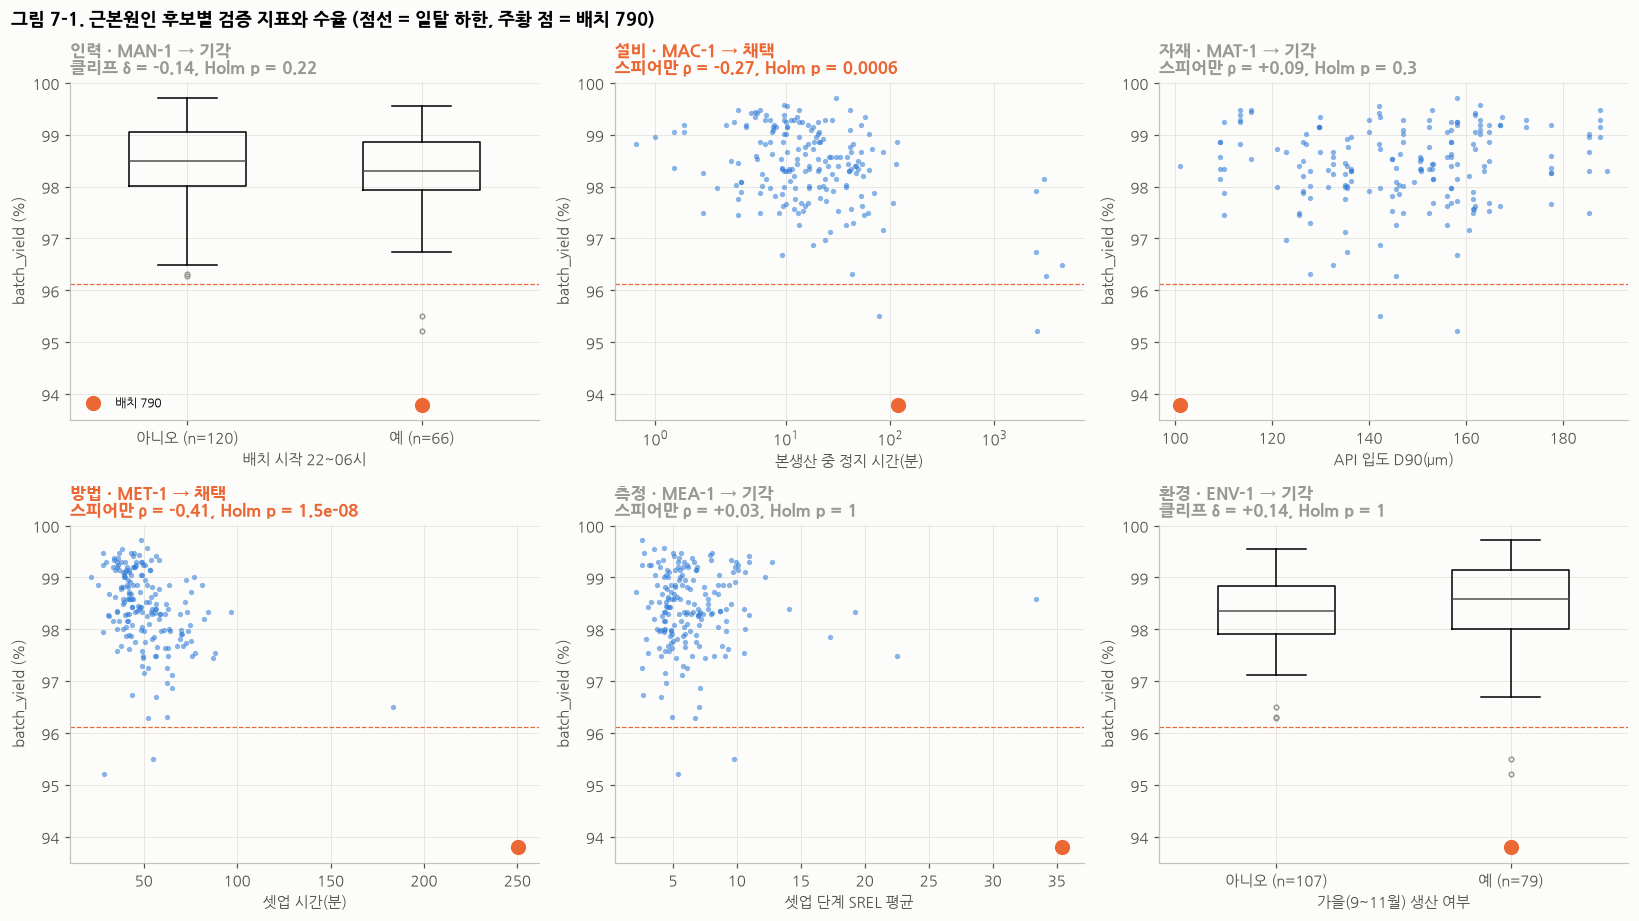

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (m_ko, _) in zip(axes.flat, M_ORDER):
    hid = FIVE_WHY[m_ko]["start"]
    h, t = HYP.loc[hid], TEST.loc[m_ko]
    color = C_LOW if t.판정 == "채택" else C_GRAY
    if h.유형 == "cont":
        ax.scatter(ref23[h.지표], ref23.batch_yield, s=12, alpha=0.55, color=C_NORMAL, linewidths=0, label="참조 배치")
        ax.scatter(d23.loc[TARGET, h.지표], d23.loc[TARGET, "batch_yield"], s=80, color=C_LOW, zorder=3, label=f"배치 {TARGET}")
        if ref23[h.지표].max() / max(ref23[h.지표].median(), 1e-9) > 8:
            ax.set_xscale("symlog")
        ax.set_xlabel(h["지표 설명"])
    else:
        groups = [ref23.loc[~ref23[h.지표].astype(bool), "batch_yield"], ref23.loc[ref23[h.지표].astype(bool), "batch_yield"]]
        ax.boxplot(groups, positions=[0, 1], widths=0.5, showfliers=True,
                   medianprops=dict(color=C_TEXT2), flierprops=dict(markersize=3, markeredgecolor=C_GRAY))
        ax.scatter(1, d23.loc[TARGET, "batch_yield"], s=80, color=C_LOW, zorder=3, label=f"배치 {TARGET}")
        ax.set_xticks([0, 1], [f"아니오 (n={len(groups[0])})", f"예 (n={len(groups[1])})"])
        ax.set_xlabel(h["지표 설명"])
    ax.axhline(sp.일탈_하한, color=C_LOW, lw=0.8, ls="--")
    ax.set_title(f"{m_ko} · {hid} → {t.판정}\n{t['② 효과 크기']}, Holm p = {t['② p (Holm)']:.2g}", color=color, fontsize=11)
    ax.set_ylabel("batch_yield (%)")
axes.flat[0].legend(loc="lower left", fontsize=8)
fig.suptitle("그림 7-1. 근본원인 후보별 검증 지표와 수율 (점선 = 일탈 하한, 주황 점 = 배치 790)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

> **해석**
>
> | 관점 | ① 790에 있었나? | ② 평소에도 수율과 연관되나? | 판정 |
> |---|---|---|---|
> | **방법 (셋업 장기화)** | 예 — 참조 중 가장 김 (p = 0.005) | **예** — ρ = −0.41, 매우 강하게 유의 | **채택** |
> | **설비 (본생산 중 정지)** | 예 — 상위 3.7% (p = 0.037) | **예** — ρ = −0.27, 유의 | **채택** |
> | 인력 (야간 착수) | 예 — 02:04 착수 | 약함 — δ = −0.14, 원 p = 0.054 → 보정 후 유의하지 않음 | 기각 |
> | 자재 (API 입도 미세) | 예 — 하위 1.1% | **아니오** — ρ = +0.09, 유의하지 않음 | 기각 |
> | 측정 (셋업 중 SREL) | 예 — 참조 중 가장 큼 | **아니오** — ρ가 0에 가까움 | 기각 |
> | 환경 (가을 생산) | 예 — 11월 | **아니오** — 오히려 가을 배치의 수율이 높은 편 | 기각 |
>
> - **자재·측정은 '790에서 극단적이었지만 원인은 아닌' 대표 사례**입니다. API 입도가 미세하거나 SREL이 컸던 다른 배치들은
>   수율이 평소와 다르지 않았습니다. 790에서 이 값들이 튄 것은 **원인이라기보다 같이 나타난 현상(동반 신호)** 으로 봐야 합니다.
>   특히 셋업 중 SREL은 압축력을 자주 바꾸면 커지는 값이라, 셋업이 길어진 결과일 가능성이 큽니다.
> - **인력(야간 착수)** 은 방향은 맞지만 증거가 약합니다. 기각하되 '조사 한계·추가 확인' 항목(근무표·교대 인수인계 기록)으로 남깁니다.

### 7.2 단계 ③ — 채택 원인의 독립성과 5 Why 중간 고리 확인

채택된 두 원인이 사실은 같은 현상이라면(예: 셋업이 길면 본생산 정지도 길다) 원인을 두 개로 세는 것은 과장입니다.
또 5 Why에서 [데이터]로 표시한 중간 고리가 제품 23 전체에서도 성립하는지 확인합니다.

In [18]:
def partial_spearman(data: pd.DataFrame, x: str, y: str, covars: list, alternative: str = "less"):
    """순위로 바꾼 뒤 공변량을 회귀로 제거하고 남은 잔차끼리 상관 (편 스피어만)."""
    r = data[[x, y] + covars].dropna().rank()
    Z = np.column_stack([np.ones(len(r))] + [r[c].to_numpy() for c in covars])
    resid = lambda v: v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]   # noqa: E731
    rho = np.corrcoef(resid(r[x].to_numpy()), resid(r[y].to_numpy()))[0, 1]
    dof = len(r) - 2 - len(covars)
    t = rho * np.sqrt(dof / (1 - rho ** 2))
    p = stats.t.cdf(t, dof) if alternative == "less" else stats.t.sf(t, dof)
    return rho, p


checks = []
# (a) 두 채택 원인은 서로 독립인가?
r_ab = stats.spearmanr(ref23.setup_min, ref23.prod_stop_min)
checks.append(("독립성", "셋업 시간 ↔ 본생산 정지 시간", "스피어만 ρ (양측)", r_ab.statistic, r_ab.pvalue, "|ρ| 작으면 별개 현상"))
for x, other, label in [("setup_min", "prod_stop_min", "셋업 시간 → 수율 | 본생산 정지 통제"),
                        ("prod_stop_min", "setup_min", "본생산 정지 → 수율 | 셋업 시간 통제")]:
    rho, p = partial_spearman(ref23, x, "batch_yield", [other])
    checks.append(("독립 효과", label, "편 스피어만 ρ (단측)", rho, p, "p < 0.05 이면 독립 효과 있음"))
# (b) 5 Why 중간 고리
mw = stats.mannwhitneyu(ref23.loc[ref23.first_in_campaign, "setup_min"], ref23.loc[~ref23.first_in_campaign, "setup_min"],
                        alternative="greater")
checks.append(("방법 Why 4", "캠페인 첫 배치 → 셋업 시간 ↑", "맨-휘트니 U (단측)",
               cliffs_delta(ref23.loc[ref23.first_in_campaign, "setup_min"], ref23.loc[~ref23.first_in_campaign, "setup_min"]),
               mw.pvalue, f"셋업 중앙값 {ref23.loc[ref23.first_in_campaign, 'setup_min'].median():.0f}분 vs "
                          f"{ref23.loc[~ref23.first_in_campaign, 'setup_min'].median():.0f}분"))
r = stats.spearmanr(ref23.fom_change, ref23.setup_min, alternative="greater")
checks.append(("방법 Why 3", "충전 장치 속도 변경 횟수 → 셋업 시간 ↑", "스피어만 ρ (단측)", r.statistic, r.pvalue, "반복 조정이 셋업을 늘리는가"))
r = stats.spearmanr(ref23.main_CompForce_sd, ref23.prod_stop_min, alternative="greater")
checks.append(("설비 Why 4", "주압축력 변동 → 본생산 정지 시간 ↑", "스피어만 ρ (단측)", r.statistic, r.pvalue, "압축부 불안정이 정지를 늘리는가"))

CHK = pd.DataFrame(checks, columns=["구분", "확인 내용", "방법", "통계량", "p", "비고"])
CHK["결과"] = np.where(CHK.구분.eq("독립성"), np.where(CHK.통계량.abs() < 0.2, "독립", "연관"),
                     np.where(CHK.p < 0.05, "지지", "지지 안 됨"))
CHK.style.format({"통계량": "{:+.2f}", "p": "{:.2g}"}).set_caption("표 7-2. 독립성과 5 Why 중간 고리 확인 (제품 23 참조 배치)")

,구분,확인 내용,방법,통계량,p,비고,결과
0,독립성,셋업 시간 ↔ 본생산 정지 시간,스피어만 ρ (양측),+0.00,0.96,|ρ| 작으면 별개 현상,독립
1,독립 효과,셋업 시간 → 수율 | 본생산 정지 통제,편 스피어만 ρ (단측),-0.43,6.8e-10,p < 0.05 이면 독립 효과 있음,지지
2,독립 효과,본생산 정지 → 수율 | 셋업 시간 통제,편 스피어만 ρ (단측),-0.29,3e-05,p < 0.05 이면 독립 효과 있음,지지
3,방법 Why 4,캠페인 첫 배치 → 셋업 시간 ↑,맨-휘트니 U (단측),+0.40,0.00042,셋업 중앙값 56분 vs 46분,지지
4,방법 Why 3,충전 장치 속도 변경 횟수 → 셋업 시간 ↑,스피어만 ρ (단측),+0.55,2.1e-16,반복 조정이 셋업을 늘리는가,지지
5,설비 Why 4,주압축력 변동 → 본생산 정지 시간 ↑,스피어만 ρ (단측),+0.34,1.1e-06,압축부 불안정이 정지를 늘리는가,지지


> **해석**
>
> - **두 채택 원인은 서로 독립입니다.** 셋업 시간과 본생산 정지 시간의 상관은 사실상 0이고, 서로를 통제해도 각각의 수율 효과가 그대로 남습니다.
>   즉 "셋업이 오래 걸린 배치"와 "본생산 중 자주 멈춘 배치"는 **서로 다른 배치에서 일어나는 별개의 문제**이며, 배치 790은 **둘이 겹친** 드문 경우입니다.
> - **방법 경로의 중간 고리가 지지됩니다.** 캠페인 첫 배치는 셋업이 더 길고(Why 4), 충전 장치를 자주 조정할수록 셋업이 길어집니다(Why 3).
> - **설비 경로의 중간 고리도 지지됩니다.** 주압축력 변동이 큰 배치일수록 본생산 중 정지가 깁니다(Why 4).
> - 남은 것은 두 경로의 **Why 5(관리상 원인)** 로, 이는 SOP·셋업 기록·설비 이력으로 현장에서 확인해야 합니다.

---
## 8. STEP 7 — RCA 결과 정리

### 8.1 채택 근본원인이 해소됐다면? (단순 추정)

채택된 두 원인이 만든 초과 폐기를 제품 23 중앙값 수준으로 되돌리면 수율이 어떻게 되는지 계산합니다.
CAPA의 기대 효과를 가늠하기 위한 **단순 산술 추정**입니다(다른 조건은 그대로라고 가정).

In [19]:
med_setup_w = lb.drop(index=TARGET)["셋업 폐기"].median()
med_prod_w = lb.drop(index=TARGET)["본생산 폐기"].median()
whatif = pd.DataFrame({
    "시나리오": ["실제 (배치 790)", "R1 해소: 셋업 폐기 → 중앙값", "R1 + R2 해소: 본생산 폐기도 → 중앙값"],
    "양품 (정)": [E["good"], E["good"] + (E["setup_w"] - med_setup_w),
                 E["good"] + (E["setup_w"] - med_setup_w) + (E["prod_w"] - med_prod_w)],
})
whatif["수율 (%)"] = whatif["양품 (정)"] / T["size"] * 100
whatif["판정"] = np.select([whatif["수율 (%)"] < sp.일탈_하한, whatif["수율 (%)"] < sp.경고_하한],
                          ["수율 일탈", "수율 이상(경고)"], "정상")
whatif.style.format({"양품 (정)": "{:,.0f}", "수율 (%)": "{:.2f}"}).hide(axis="index") \
      .set_caption(f"표 8-1. 근본원인 해소 시 추정 수율 (일탈 하한 {sp.일탈_하한:.2f}%, 경고 하한 {sp.경고_하한:.2f}%)")

시나리오,양품 (정),수율 (%),판정
실제 (배치 790),"900,451",93.80,수율 일탈
R1 해소: 셋업 폐기 → 중앙값,"925,384",96.39,수율 이상(경고)
R1 + R2 해소: 본생산 폐기도 → 중앙값,"932,596",97.15,정상


> **해석**
>
> - **R1(셋업)만 해소해도 수율은 일탈 하한을 넘습니다(약 96.4%).** 다만 경고 하한(96.9%)에는 못 미칩니다.
> - **R1과 R2를 모두 해소하면 약 97.1%로 정상 범위**에 들어갑니다. 두 원인 모두에 대한 CAPA가 필요하다는 근거입니다.
> - 남는 차이(중앙값 98.4%와의 약 1.3%p)는 주로 평소의 4배가 넘는 **미기록 손실** 때문이며, 이 데이터로는 원인을 알 수 없습니다.

### 8.2 특성요인도 (검정 후)

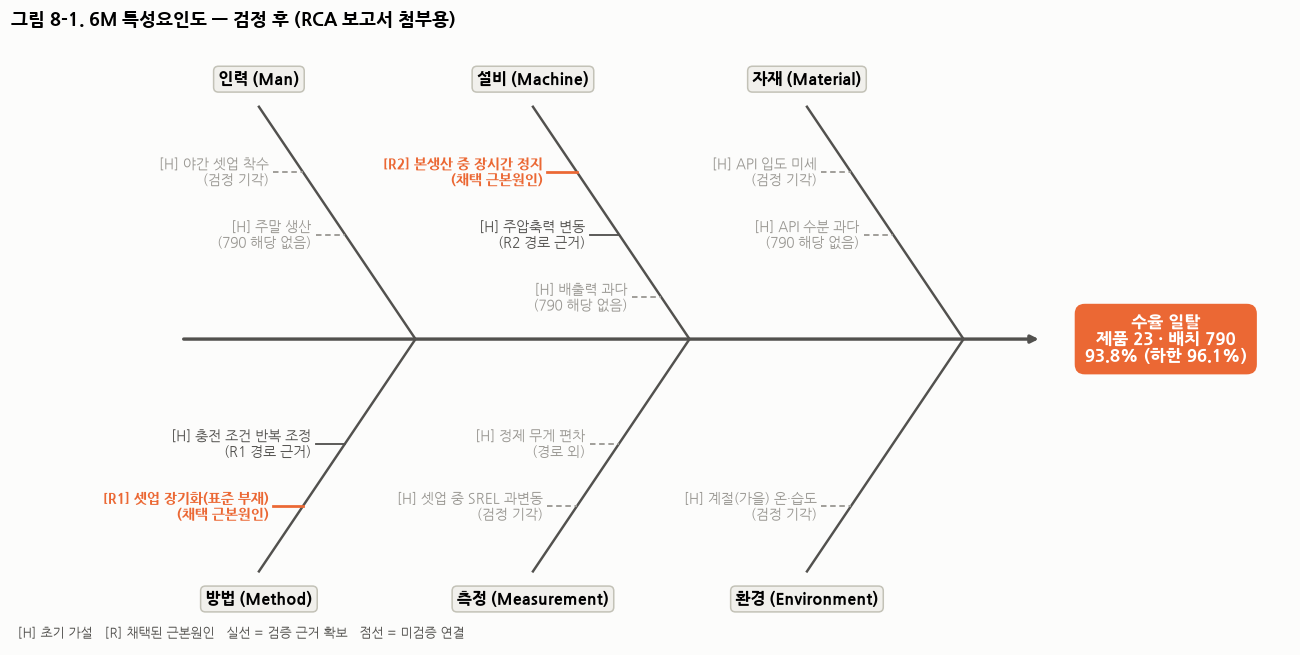

In [20]:
R_TAG = {"방법": "R1", "설비": "R2"}       # 손실 기여가 큰 순서로 번호 부여
status = {}
for hid in HYP.index:
    m_ko = HYP.loc[hid, "6M"]
    start = FIVE_WHY[m_ko]["start"]
    if hid == start and TEST.loc[m_ko, "판정"] == "채택":
        status[hid] = (R_TAG[m_ko], True, True, "(채택 근본원인)")
    elif hid == start:
        status[hid] = ("H", False, False, "(검정 기각)")
    elif hid in ("MET-2", "MAC-2"):
        status[hid] = ("H", True, False, f"({'R1' if hid == 'MET-2' else 'R2'} 경로 근거)")
    else:
        status[hid] = ("H", False, False, "(790 해당 없음)" if HYP.loc[hid, "관찰 판정"] == "해당 없음" else "(경로 외)")
draw_fishbone(status, "그림 8-1. 6M 특성요인도 — 검정 후 (RCA 보고서 첨부용)", HEAD)

### 8.3 근본원인 조사 보고서 (RCA)

팀 공용 양식의 **RCA보고서 탭** 항목을 따릅니다. 6M 특성요인도는 위 그림 8-1을 첨부합니다.

In [21]:
def root_sentence(m_ko):
    return FIVE_WHY[m_ko]["chain"][-1][1].replace("**", "")


PATH = {
    "방법": f"수율 {E['yield']:.1f}% → 셋업 폐기 {E['setup_w']:,.0f}정 → 셋업 {E['setup_min']:.0f}분 지연 → "
            f"충전 깊이·압축력 시행착오 조정(충전 장치 변경 {V('fom_change'):.0f}회) → 제품 교체 첫 배치 → 표준 셋업 조건·완료 판정 기준 부재",
    "설비": f"수율 {E['yield']:.1f}% → 본생산 폐기 {E['prod_w']:,.0f}정 → 본생산 중 정지 {E['pstop']:.0f}분(1분 이상 정지 {E['nstops']:.0f}회) → "
            f"운전 중 조건 이탈로 정지·재조정 → 압축부 불안정(주압축력 변동 상위 {HYP.loc['MAC-2', '극단 백분위']:.1%}) → 재시작 안정화 절차·압축부 점검 기준 부재",
}


def path_text(m_ko):
    return PATH[m_ko]


t_r1, t_r2 = TEST.loc["방법"], TEST.loc["설비"]
c_ind = CHK.set_index("확인 내용")
rejected = TEST[TEST.판정 == "기각"]
other_txt = "<br>".join(
    f"• {m_ko}({r_.가설}, {HYP.loc[r_.가설, '원인 후보']}): 790 해당 {'예' if r_['① 통과'] else '아니오'}, "
    f"수율 연관 {r_['② 효과 크기']}, Holm p = {r_['② p (Holm)']:.2g} → 기각"
    for m_ko, r_ in rejected.iterrows())
other_txt += "<br>• 790에서 관찰되지 않아 경로 출발점에서 제외: " + ", ".join(
    f"{i}({SHORT[i]})" for i in HYP.index[HYP['관찰 판정'] == '해당 없음'])

report2 = form_html("근본원인 조사 보고서 (RCA)", f"RCA-{EVENT_START:%Y-%m%d}-{TARGET} <i>(예시 번호, 발생보고서 {INC_NO} 연계)</i>", [
    ("§", "1. 조사 기본정보"),
    ("담당부서", "생산기술팀", "담당자", "공정 엔지니어 (가명) [가상]"),
    ("조사 시작일시", f"{EVENT_END + pd.Timedelta(days=1):%Y.%m.%d.} 09:00 [가상]", "조사 종료일시", f"{EVENT_END + pd.Timedelta(days=3):%Y.%m.%d.} 17:00 [가상]"),
    ("대상 제품", "제품 23 (20 mg 정제)", "배치 번호", str(TARGET)),
    ("대상 공정", "타정", "대상 설비", "타정기 (설비 번호 데이터 미제공)"),
    ("조사 시스템", "<b>■ MES</b>(타정기 운전 시계열·공정 요약) &nbsp; <b>■ LIMS</b>(원료·IPC·출하 시험) &nbsp; □ QMS &nbsp; <b>■ 설비 이력</b>(10초 운전 기록) &nbsp; □ 기타"),
    ("조사 데이터", "MES: Process.zip(제품 23 10초 시계열 — 속도·충전 깊이·압축력·SREL·생산/폐기 카운터), Process.csv(배치 공정 요약) / "
                   "LIMS: Laboratory.csv(API·부형제 물성·로트, IPC, 수율, 출하 품질)"),
    ("조사 기간 및 비교 범위", f"제품 23 전체 {len(d23)}개 배치({d23.start_month.min():%Y-%m} ~ {d23.start_month.max():%Y-%m}). "
                             f"비교 기준 = 배치 {TARGET}를 제외한 {len(ref23)}개 배치."),
    ("§", "2. 관찰된 문제 및 조사 결과"),
    ("관찰된 문제", f"타정 공정 수율 일탈 — 캠페인 {E['campaign']} 첫 배치에서 셋업 {E['setup_min']:.0f}분 지연 및 본생산 중 정지 {E['pstop']:.0f}분 발생"),
    ("대상 배치 수율", f"{E['yield']:.1f}% (일탈 하한 {E['limit']:.1f}%)", "비교 배치 평균 수율", f"{E['n_ref']}개 배치 / 평균 {E['ref_mean']:.1f}%"),
    ("손실 내역 및 물질수지", f"이론 {T['size']:,.0f}정 = 양품 {E['good']:,.0f} + 셋업 폐기 {E['setup_w']:,.0f}({E['setup_share']:.0%}) "
                            f"+ 본생산 폐기 {E['prod_w']:,.0f}({E['prod_share']:.0%}) + 미기록 손실 {E['unrec']:,.0f}({E['unrec_share']:.0%}) 정 "
                            f"/ 질량 환산(추정): 투입 {MASS_IN:,.1f} kg, 양품 {MASS_OUT:,.1f} kg"),
    ("§", "3. 특성요인도 및 6M 조사"),
    ("6M 특성요인도", "그림 8-1 첨부 (6M × 후보 12개)"),
    ("범주 및 표시", "범주: 인력 / 설비 / 자재 / 방법 / 측정 / 환경 &nbsp;|&nbsp; 표시: [H] 초기 가설 / [R] 채택된 근본원인 / 실선 = 검증 근거 확보 / 점선 = 미검증 연결"),
    ("기타 가설 검토 결과", other_txt),
    ("상세 조사 기록 및 검증 근거", "본 노트북 `notebooks/RCA_Lek_yield_deviation.ipynb` — 5장(6M 후보 표 5-1), 6장(5 Why), 7장(검정 표 7-1·7-2)"),
    ("§", "4. 채택된 근본원인 및 근거"),
    ("R1 근본원인", f"<b>[방법] {root_sentence('방법')}</b> 그 결과 제품 교체 첫 배치의 셋업이 {E['setup_min']:.0f}분으로 길어지며 "
                   f"충전 깊이·압축력 시행착오 조정 중 {E['setup_w']:,.0f}정이 폐기되었다."),
    ("R1 채택 이유 및 검증 근거",
     f"① 790 셋업 시간이 참조 {len(ref23)}개 배치 중 최장(경험적 p = {t_r1['① 790 극단 p']:.3f}). "
     f"② 제품 23에서 셋업이 길수록 수율이 낮음({t_r1['② 효과 크기']}, Holm p = {t_r1['② p (Holm)']:.2g}). "
     f"③ 본생산 정지를 통제해도 효과 유지(편 ρ = {c_ind.loc['셋업 시간 → 수율 | 본생산 정지 통제', '통계량']:+.2f}). "
     f"중간 고리: 캠페인 첫 배치의 셋업이 더 길고(p = {c_ind.loc['캠페인 첫 배치 → 셋업 시간 ↑', 'p']:.2g}), "
     f"충전 장치 조정이 잦을수록 셋업이 길어짐(ρ = {c_ind.loc['충전 장치 속도 변경 횟수 → 셋업 시간 ↑', '통계량']:+.2f})."),
    ("R2 근본원인", f"<b>[설비] {root_sentence('설비')}</b> 그 결과 본생산 중 정지가 {E['pstop']:.0f}분, 1분 이상 정지가 {E['nstops']:.0f}회 발생하고 "
                   f"재시작마다 폐기가 누적되어 {E['prod_w']:,.0f}정이 폐기되었다."),
    ("R2 채택 이유 및 검증 근거",
     f"① 790 본생산 정지 시간이 참조 배치 상위 {t_r2['① 790 극단 p']:.1%}. "
     f"② 제품 23에서 본생산 정지가 길수록 수율이 낮음({t_r2['② 효과 크기']}, Holm p = {t_r2['② p (Holm)']:.2g}). "
     f"③ 셋업 시간과 독립(ρ = {c_ind.loc['셋업 시간 ↔ 본생산 정지 시간', '통계량']:+.2f}), 셋업 통제 후에도 효과 유지"
     f"(편 ρ = {c_ind.loc['본생산 정지 → 수율 | 셋업 시간 통제', '통계량']:+.2f}). "
     f"중간 고리: 주압축력 변동이 클수록 본생산 정지가 김(ρ = {c_ind.loc['주압축력 변동 → 본생산 정지 시간 ↑', '통계량']:+.2f})."),
    ("R3 근본원인", "해당 없음 (본 사례는 2개 원인 채택)"),
    ("5Why 분석 경로", f"<b>R1</b>: {path_text('방법')}<br><b>R2</b>: {path_text('설비')}"),
    ("조사 한계 및 추가 확인",
     "① 두 근본원인의 Why 5(관리상 원인)는 데이터로 직접 확인 불가 → 제품 교체 SOP·셋업 기록, 재시작 절차, 압축부 정비 이력 검토 필요. "
     f"② 미기록 손실 {E['unrec']:,.0f}정({E['unrec_share']:.0%}, 제품 23 중앙값의 {E['unrec'] / lb.drop(index=TARGET)['미기록 손실'].median():.1f}배)은 "
     "잔류·집진·샘플링 기록이 없어 원인 미확정 → 해당 기록 확인 필요. "
     "③ 야간 착수(인력)는 방향은 맞으나 통계적으로 약함 → 근무표·교대 인수인계 기록으로 추가 확인. "
     "④ 온·습도 데이터 부재로 환경 요인은 계절 대리 지표로만 검토. "
     "⑤ 관찰 데이터 기반의 연관성 검정이므로 인과는 CAPA 시행 후 효과성 평가로 최종 확인."),
])
display(HTML(report2))

### 8.4 RCA 결론 요약

**한 줄 결론** — 배치 790의 수율 일탈(93.8%)은 **제품 교체 셋업 표준 부재로 인한 셋업 장기화(R1, 손실의 53%)** 와
**재시작 안정화 절차·압축부 점검 기준 부재로 인한 본생산 중 정지·재시작 반복(R2, 손실의 13%)** 이 겹쳐 발생했습니다.

| 구분 | 내용 |
|---|---|
| 채택 근본원인 | **R1 [방법]** 제품별 표준 셋업 조건·셋업 완료 판정 기준 미정립 &nbsp;/&nbsp; **R2 [설비]** 재시작 후 조건 안정화 확인 절차·압축부 점검 기준 미비 |
| 기각된 후보 | 인력(야간 착수) · 자재(API 입도) · 측정(셋업 중 SREL) · 환경(계절) — 790에서 관찰됐지만 **평소 수율과 연관되지 않음** |
| 기대 효과 | R1 해소 시 약 96.4%(일탈 해소), R1+R2 해소 시 약 97.1%(정상 범위) — 단순 추정 |
| 남은 과제 | Why 5 현장 확인, 미기록 손실 34%, 야간 근무 영향 추가 확인 |

### 8.5 다음 단계 — QA의 CAPA로 넘길 내용 (제안)

팀 CAPA 양식은 **RCA 번호(R)별로 시정조치 1개 + 예방조치 1개**를 가정합니다. 아래는 공정 엔지니어 관점의 **초안 제안**이며,
조치 확정·책임자·기한·유효성 평가 계획은 QA가 정합니다.

| 조치 ID | 유형 | 연계 원인 | 조치 제안 | 유효성 평가 지표 (예시) |
|---|---|---|---|---|
| CA-R1-01 | 시정 | R1 | 제품 23 표준 셋업 조건(초기 충전 깊이·주압축력)을 과거 정상 배치 셋업 기록에서 도출해 셋업 SOP에 명시, 셋업 완료 판정 기준 추가 | 제품 23 캠페인 첫 배치 셋업 시간·셋업 폐기 (중앙값 이하) |
| PA-R1-01 | 예방 | R1 | 셋업 시간이 긴 다른 제품으로 표준 셋업 조건 정립 확대, 셋업 시간 경고 기준(예: 중앙값 + 3σ̂) 운영 | 전 제품 셋업 시간 경고 발생 건수 |
| CA-R2-01 | 시정 | R2 | 타정기 압축부 점검·정비, 재시작 후 조건 안정화 확인 항목(충전 깊이·압축력 확인 후 양품 계수)을 운전 SOP에 추가 | 본생산 중 정지 시간·본생산 폐기 |
| PA-R2-01 | 예방 | R2 | 주압축력 변동(표준편차) 실시간 경고 → 정지 전에 점검 유도 | 주압축력 변동 경고 대비 정지 발생률 |

### 8.6 RCA Agent 설계와의 연결

이 노트북의 각 단계는 멀티 에이전트 시스템의 RCA 흐름에서 **하나의 노드(도구)** 로 옮길 수 있습니다.

| RCA 단계 | 이 노트북 구현 | Agent 노드·도구로 옮길 때 |
|---|---|---|
| STEP 1 일탈 판정 | `spec`, `judge()` | 수율 모니터링 노드: 제품별 관리 기준 조회 → 판정 → 일탈 이벤트 생성 |
| STEP 2 5W1H | 시계열 지표, 손실 분해, `E` | 문제 정의 노드: 배치 시계열·물질수지 조회 도구 → 5W1H 초안 |
| STEP 3 발생보고서 | `form_html()` 발생보고서 | 보고서 생성 노드: 양식 템플릿 + 계산값 채우기 (가상 항목은 사람 입력) |
| STEP 4 6M 후보 | `HYP` 표, `extremity()` | 가설 생성 노드(LLM) + 관찰 근거 계산 도구(참조 분포 대비 극단 백분위) |
| STEP 5 5 Why | `FIVE_WHY` | 추론 노드(LLM): [데이터]/[추정] 태그 강제, 검증 고리·지표 지정 |
| STEP 6 검정 | `association_test()`, `holm()`, `partial_spearman()` | 가설 검증 도구: 2단계 검정 + 다중비교 보정 → 채택/기각 |
| STEP 7 RCA 보고서 | `form_html()` RCA보고서, 특성요인도 | 보고서 생성 노드 → QA CAPA 노드로 R별 원인 전달 |